# Brevitas Quantization Workshop 19.10.2026

### From a quantization-aware PyTorch model to a hardware-ready quantized ONNX graph

This notebook is a hands-on introduction to the **QONNX** ecosystem and to **Brevitas**, the
quantization-aware training (QAT) library that feeds it.

**What you will do**

| Part | Topic |
|---|---|
| 1 | Build, run and edit plain ONNX graphs with QONNX's `ModelWrapper` |
| 2 | Understand the `Quant` operator and the QONNX datatype system |
| 3 | Load real quantized models, analyse them, estimate their inference cost |
| 4 | Write and compose transformation passes |
| 5 | Train a quantized network with **Brevitas** |
| 6 | Export Brevitas → QONNX, verify numerics, sweep bit widths, convert to QCDQ |
| 7 | Where to go next (FINN, hls4ml, the CLI tools) |

**What QONNX is.**

ONNX has no native way to express *arbitrary-precision* quantization: its
`QuantizeLinear`/`DequantizeLinear` pair is restricted to 8-bit (and, more recently, 4-bit)
integer tensor types. QONNX adds a small set of custom operators — `Quant`, `BipolarQuant`,
`FloatQuant`, `Trunc` — that keep tensors in `float32` containers while *annotating* the
quantization grid they live on. That lets you describe a 2-bit weight, a 3-bit activation or an
E4M3 minifloat in a standard ONNX file, which is exactly what FPGA/ASIC toolchains such as
[FINN](https://github.com/Xilinx/finn) and [hls4ml](https://github.com/fastmachinelearning/hls4ml)
need.

*Based on the notebooks in [fastmachinelearning/qonnx](https://github.com/fastmachinelearning/qonnx/tree/main/notebooks)
and [onnx/tutorials](https://github.com/onnx/tutorials).*

## 0. Setup

### 0.1 Install

Install Brevitas with the `export` extra — that pulls in `qonnx`, `onnxscript`, `onnxoptimizer`.

In [129]:
import importlib, subprocess, sys

def _ensure(pkgs, test_imports):
    missing = [m for m in test_imports if importlib.util.find_spec(m) is None]
    if missing:
        print("installing:", pkgs)
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *pkgs])
    else:
        print("already present:", ", ".join(test_imports))

# brevitas[export] brings qonnx + onnx (pinned) + onnxruntime + onnxscript + onnxoptimizer
_ensure(["brevitas[export]", "netron", "matplotlib"],
        ["brevitas", "qonnx", "onnx", "onnxruntime", "netron", "matplotlib"])

already present: brevitas, qonnx, onnx, onnxruntime, netron, matplotlib


### 0.2 Versions checks

In [130]:
import importlib.metadata as md
import onnx, onnxruntime as rt

for p in ["qonnx", "brevitas", "onnx", "onnxruntime", "onnxscript", "torch", "numpy"]:
    try:
        print(f"{p:12s} {md.version(p)}")
    except md.PackageNotFoundError:
        print(f"{p:12s} (not installed)")
print(f"{'onnx IR':12s} {onnx.IR_VERSION}")

qonnx        1.0.0
brevitas     0.13.4
onnx         1.23.2
onnxruntime  1.31.0
onnxscript   0.7.2
torch        2.11.0+cpu
numpy        2.1.3
onnx IR      14


In [131]:
import os
from pathlib import Path

def patch_onnxruntime_ir_version():
    """Make onnxruntime tolerate models whose IR version is newer than it supports.

    Returns the highest IR version the installed runtime accepts, or None if already patched.
    """
    if getattr(rt, "_ir_clamp_installed", False):
        return None
    original = rt.InferenceSession

    def probe_max_ir():
        ident = onnx.helper.make_node("Identity", ["x"], ["y"])
        vi = onnx.helper.make_tensor_value_info("x", onnx.TensorProto.FLOAT, [1])
        vo = onnx.helper.make_tensor_value_info("y", onnx.TensorProto.FLOAT, [1])
        probe = onnx.helper.make_model(onnx.helper.make_graph([ident], "probe", [vi], [vo]))
        for ir in range(probe.ir_version, 2, -1):
            probe.ir_version = ir
            try:
                original(probe.SerializeToString())
                return ir
            except Exception as e:
                if "IR version" not in str(e):
                    return ir
        return onnx.IR_VERSION

    cap = probe_max_ir()

    class ClampingInferenceSession(original):
        def __init__(self, path_or_bytes, *args, **kwargs):
            try:
                super().__init__(path_or_bytes, *args, **kwargs)
                return
            except Exception as e:
                if "IR version" not in str(e):
                    raise
            if isinstance(path_or_bytes, (str, Path, os.PathLike)):
                proto = onnx.load(str(path_or_bytes))
            else:
                proto = onnx.load_from_string(bytes(path_or_bytes))
            proto.ir_version = min(proto.ir_version, cap)
            super().__init__(proto.SerializeToString(), *args, **kwargs)

    rt.InferenceSession = ClampingInferenceSession
    rt._ir_clamp_installed = True
    return cap

_cap = patch_onnxruntime_ir_version()
print(f"onnxruntime accepts IR <= {_cap}; onnx produces IR {onnx.IR_VERSION}")

onnxruntime accepts IR <= None; onnx produces IR 14


### 0.3 Workshop helpers

Four small utilities we will reuse throughout:

* `showInNetron` — interactive graph viewer. Set the environment variable `WORKSHOP_NETRON=0`
  to fall back to a text summary (useful in headless runs, or when the iframe is blocked).
* `summarize_model` — compact, always-available text view of a graph: nodes, op types, shapes.
* `showSrc` — print the source of a function or class, so you can read the implementation of
  the QONNX passes you are calling.
* `ort_session` — build an `onnxruntime` session from a `ModelWrapper` or a raw `ModelProto`
  (IR-version repair is already handled globally by the §0.2 shim).

In [132]:
import copy, inspect, os, re
import onnxruntime as rt
from qonnx.core.modelwrapper import ModelWrapper

#USE_NETRON = os.getenv("WORKSHOP_NETRON", "1") == "1"
USE_NETRON = os.getenv("WORKSHOP_NETRON", "1") == "0"


def showSrc(what):
    """Print the source code of a function/class."""
    print("".join(inspect.getsourcelines(what)[0]))


def summarize_model(model, max_nodes: int = 40):
    """Text summary of an ONNX graph: works everywhere, no server needed."""
    m = ModelWrapper(model) if isinstance(model, str) else model
    g = m.graph
    print(f"graph '{g.name}'   nodes: {len(g.node)}   initializers: {len(g.initializer)}")
    print("opset imports:", [(o.domain or "<default>", o.version) for o in m.model.opset_import],
          f"  ir_version={m.model.ir_version}")
    for t in list(g.input) + list(g.output):
        kind = "in " if t in g.input else "out"
        print(f"  {kind} {t.name:28s} {m.get_tensor_shape(t.name)}  {m.get_tensor_datatype(t.name)}")
    print(f"  {'-'*68}")
    for i, n in enumerate(g.node[:max_nodes]):
        dom = f" [{n.domain}]" if n.domain else ""
        print(f"  {i:3d} {n.op_type+dom:38s} {list(n.input)} -> {list(n.output)}")
    if len(g.node) > max_nodes:
        print(f"  ... {len(g.node)-max_nodes} more nodes")


def showInNetron(model_filename: str, localhost_url: str = None, port: int = None):
    """Show an ONNX model in the notebook using Netron; text summary as fallback."""
    if not USE_NETRON:
        print(f"[netron disabled] {model_filename}")
        return summarize_model(model_filename)
    try:
        import netron
        from IPython.display import IFrame
        try:
            port = port or int(os.getenv("NETRON_PORT", default="8081"))
        except ValueError:
            port = 8081
        localhost_url = localhost_url or os.getenv("LOCALHOST_URL", default="localhost")
        netron.start(model_filename, address=("0.0.0.0", port), browse=False)
        return IFrame(src=f"http://{localhost_url}:{port}/", width="100%", height=400)
    except Exception as e:                                    # headless / blocked iframe
        print(f"[netron unavailable: {type(e).__name__}] falling back to text summary")
        return summarize_model(model_filename)


def ort_session(model):
    """onnxruntime InferenceSession from a ModelWrapper or a ModelProto."""
    proto = model.model if isinstance(model, ModelWrapper) else model
    return rt.InferenceSession(copy.deepcopy(proto).SerializeToString())


print("helpers ready; netron enabled:", USE_NETRON)

helpers ready; netron enabled: False


---
# 1. QONNX — how to work with models

We start with a plain (unquantized) ONNX graph of simple arithmetic, so that the graph-surgery
mechanics are not tangled up with quantization semantics.

### 1.1 Creating a simple ONNX model

Every node comes from the [standard ONNX operator set](https://onnx.ai/onnx/operators/).
`onnx.helper.make_node` takes the op type, the names of the input tensors, the names of the
output tensors, and a node name. The tensor *names* are what wires the graph together.

In [133]:
import onnx
from qonnx.util.basic import qonnx_make_model, get_preferred_onnx_opset, get_preferred_qonnx_opset

Add1_node = onnx.helper.make_node("Add", inputs=["in1", "in2"], outputs=["sum1"], name="Add1")
Add2_node = onnx.helper.make_node("Add", inputs=["sum1", "in3"], outputs=["sum2"], name="Add2")
Abs_node  = onnx.helper.make_node("Abs", inputs=["sum2"], outputs=["abs1"], name="Abs")
Add3_node = onnx.helper.make_node("Add", inputs=["abs1", "abs1"], outputs=["sum3"], name="Add3")
Round_node = onnx.helper.make_node("Round", inputs=["sum3"], outputs=["out1"], name="Round")

print(Add1_node)

input: "in1"
input: "in2"
output: "sum1"
name: "Add1"
op_type: "Add"



In ONNX every data edge is a tensor, and every tensor needs a declared element type and
shape. `make_tensor_value_info` creates those declarations for the graph inputs/outputs; the
remaining internal edges go into `value_info`.

**Important:** here the shape never changes along the graph. In general it does — you are
responsible for declaring shapes consistently, or for running shape inference afterwards (§4).

In [134]:
def f32(name, shape=(4, 4)):
    return onnx.helper.make_tensor_value_info(name, onnx.TensorProto.FLOAT, list(shape))

graph = onnx.helper.make_graph(
    nodes=[Add1_node, Add2_node, Abs_node, Add3_node, Round_node],  # must be topologically sorted
    name="simple_graph",
    inputs=[f32("in1"), f32("in2"), f32("in3")],
    outputs=[f32("out1")],
    value_info=[f32("sum1"), f32("sum2"), f32("abs1"), f32("sum3")],
)
print(f"{len(graph.node)} nodes, {len(graph.input)} inputs, {len(graph.output)} outputs")

5 nodes, 3 inputs, 1 outputs


Now wrap the graph in a model. Use **`qonnx_make_model`** rather than `onnx.helper.make_model`:
it stamps the model with the ONNX opset QONNX prefers *and* registers the
`qonnx.custom_op.general` domain, so `Quant` nodes you add later are legal in the same file.

In [135]:
onnx_model = qonnx_make_model(graph, producer_name="simple-model")
onnx.save(onnx_model, "simple_model.onnx")

print("preferred ONNX opset :", get_preferred_onnx_opset())
print("preferred QONNX opset:", get_preferred_qonnx_opset())
print("opset imports        :", [(o.domain or "<default>", o.version) for o in onnx_model.opset_import])

preferred ONNX opset : 11
preferred QONNX opset: 1
opset imports        : [('<default>', 11), ('qonnx.custom_op.general', 1)]


In [136]:
showInNetron("simple_model.onnx")

[netron disabled] simple_model.onnx
graph 'simple_graph'   nodes: 5   initializers: 0
opset imports: [('<default>', 11), ('qonnx.custom_op.general', 1)]   ir_version=14
  in  in1                          [4, 4]  FLOAT32
  in  in2                          [4, 4]  FLOAT32
  in  in3                          [4, 4]  FLOAT32
  out out1                         [4, 4]  FLOAT32
  --------------------------------------------------------------------
    0 Add                                    ['in1', 'in2'] -> ['sum1']
    1 Add                                    ['sum1', 'in3'] -> ['sum2']
    2 Abs                                    ['sum2'] -> ['abs1']
    3 Add                                    ['abs1', 'abs1'] -> ['sum3']
    4 Round                                  ['sum3'] -> ['out1']


### 1.2 Running the model and checking it

Netron tells you the graph *looks* right. To know that it *is* right, execute it. Write the
reference computation in NumPy first.

In [137]:
import numpy as np

def expected_output(in1, in2, in3):
    sum1 = np.add(in1, in2)
    sum2 = np.add(sum1, in3)
    abs1 = np.absolute(sum2)
    sum3 = np.add(abs1, abs1)
    return np.round(sum3)

rng = np.random.default_rng(0)
input_dict = {k: rng.uniform(-5, 5, (4, 4)).astype(np.float32) for k in ("in1", "in2", "in3")}
ref_output = expected_output(**input_dict)
print(ref_output)

[[ 3.  1. 13. 15.]
 [ 3.  9. 14.  5.]
 [ 5.  3. 18.  4.]
 [ 9.  1.  3.  6.]]


[ONNX Runtime](https://github.com/microsoft/onnxruntime) is the reference execution engine
for standard ONNX. We go through the `ort_session` helper from §0.3 so that an IR-version skew
is repaired rather than fatal.

> **Round-to-even.** ONNX `Round` — like NumPy's `np.round` and like the default
> `rounding_mode="ROUND"` of the QONNX `Quant` op — rounds halves to the nearest *even*
> value, not away from zero. `2.5 -> 2`, `3.5 -> 4`. This matters when you later compare a
> quantized model against a hand-written reference.

In [138]:
sess = ort_session(onnx_model)
output = sess.run(None, input_dict)

print("ONNX Runtime:\n", output[0])
print("\nreference:\n", ref_output)
assert np.array_equal(output[0], ref_output), "model output does not match the reference!"
print("\nThe results are the same.")

ONNX Runtime:
 [[ 3.  1. 13. 15.]
 [ 3.  9. 14.  5.]
 [ 5.  3. 18.  4.]
 [ 9.  1.  3.  6.]]

reference:
 [[ 3.  1. 13. 15.]
 [ 3.  9. 14.  5.]
 [ 5.  3. 18.  4.]
 [ 9.  1.  3.  6.]]

The results are the same.


### 1.3 Manipulating a graph

Two consecutive `Add` nodes can be replaced by a single [`Sum`](https://onnx.ai/onnx/operators/onnx__Sum.html)
node, which accepts more than two inputs. Pretend we do not know the graph and have to *find*
the pattern first.

This is where QONNX's [`ModelWrapper`](https://github.com/fastmachinelearning/qonnx/blob/main/src/qonnx/core/modelwrapper.py)
earns its keep: a thin wrapper around `ModelProto` with graph-navigation and tensor-metadata
helpers on top.

In [139]:
from qonnx.core.modelwrapper import ModelWrapper

qonnx_model = ModelWrapper(onnx_model)
print([m for m in dir(ModelWrapper) if not m.startswith("_")])

['T', 'analysis', 'check_all_tensor_shapes_specified', 'cleanup', 'del_initializer', 'find_consumer', 'find_consumers', 'find_direct_predecessors', 'find_direct_successors', 'find_producer', 'find_upstream', 'get_all_tensor_names', 'get_customop_wrapper', 'get_finn_nodes', 'get_first_global_in', 'get_first_global_out', 'get_initializer', 'get_metadata_prop', 'get_node_from_name', 'get_node_index', 'get_nodes_by_op_type', 'get_non_finn_nodes', 'get_opset_imports', 'get_tensor_datatype', 'get_tensor_fanout', 'get_tensor_layout', 'get_tensor_shape', 'get_tensor_sparsity', 'get_tensor_valueinfo', 'graph', 'is_fork_node', 'is_join_node', 'make_empty_exec_context', 'make_new_valueinfo_name', 'make_subgraph_modelwrapper', 'model', 'rename_tensor', 'save', 'set_initializer', 'set_metadata_prop', 'set_opset_import', 'set_tensor_datatype', 'set_tensor_layout', 'set_tensor_shape', 'set_tensor_sparsity', 'temporary_fix_oldstyle_domain', 'transform', 'transform_subgraphs']


#### The hand-written way

Useful to see once, because it shows exactly what the library does for you.

In [140]:
def get_node_id(model):
    return {node.name: i for i, node in enumerate(model.graph.node)}

def identify_nodes(model, op_type):
    return [n for n in model.graph.node if n.op_type == op_type]

def find_predecessor(model, node):
    return [model.find_producer(i) for i in node.input]

def find_successor(model, node):
    return [model.find_consumer(o) for o in node.output]

print("node ids    :", get_node_id(qonnx_model))
print("adder nodes :", [n.name for n in identify_nodes(qonnx_model, "Add")])

node ids    : {'Add1': 0, 'Add2': 1, 'Abs': 2, 'Add3': 3, 'Round': 4}
adder nodes : ['Add1', 'Add2', 'Add3']


#### The built-in way

`ModelWrapper` already ships all four functions:

| hand-written | built-in |
|---|---|
| `get_node_id(model)[name]` | `model.get_node_index(node)` |
| `identify_nodes(model, "Add")` | `model.get_nodes_by_op_type("Add")` |
| `find_predecessor(model, node)` | `model.find_direct_predecessors(node)` |
| `find_successor(model, node)` | `model.find_direct_successors(node)` |

The built-ins also behave correctly on **fork/join** nodes (a tensor consumed by several nodes),
where `find_consumer` returns only the first consumer and silently loses the rest.
`model.is_fork_node(n)` / `model.is_join_node(n)` tell you when that matters.

In [141]:
add_nodes = qonnx_model.get_nodes_by_op_type("Add")
for n in add_nodes:
    print(f"{n.name:6s} idx={qonnx_model.get_node_index(n)}  "
          f"fork={qonnx_model.is_fork_node(n)} join={qonnx_model.is_join_node(n)}  "
          f"pred={[p.name for p in (qonnx_model.find_direct_predecessors(n) or [])]}  "
          f"succ={[s.name for s in (qonnx_model.find_direct_successors(n) or [])]}")

Add1   idx=0  fork=False join=False  pred=[]  succ=['Add2']
Add2   idx=1  fork=False join=False  pred=['Add1']  succ=['Abs']
Add3   idx=3  fork=False join=True  pred=['Abs', 'Abs']  succ=['Round']


Now find an `Add` whose successor is also an `Add` — that is the pair we can fuse.

In [142]:
def adder_pairs(model):
    pairs = []
    for node in model.get_nodes_by_op_type("Add"):
        for succ in (model.find_direct_successors(node) or []):
            if succ.op_type == "Add":
                pairs.append((node, succ))
    return pairs

pairs = adder_pairs(qonnx_model)
for a, b in pairs:
    print(f"{a.name} -> {b.name} can become a single Sum node")
assert len(pairs) == 1
substitute_pair = pairs[0]

Add1 -> Add2 can become a single Sum node


The new `Sum` node takes every input of the pair **except** the tensor that carried the
intermediate result, and produces the second adder's output.

In [143]:
first, second = substitute_pair
internal = set(first.output) | set(second.output)
input_list = [t for n in substitute_pair for t in n.input if t not in internal]
sum_output = second.output[0]
print("new inputs:", input_list, "-> output:", sum_output)

Sum_node = onnx.helper.make_node("Sum", inputs=input_list, outputs=[sum_output], name="Sum")

new inputs: ['in1', 'in2', 'in3'] -> output: sum2


Insert at the index of the *first* node of the pair so the graph stays topologically
sorted, then delete the originals. `.insert()`/`.remove()` are plain protobuf list operations.

Note we edit `qonnx_model.graph`, not the `graph` variable from §1.1 — always go through the
wrapper, so you cannot accidentally desynchronise the two views of the same model.

In [144]:
g = qonnx_model.graph
g.node.insert(qonnx_model.get_node_index(first), Sum_node)
for node in substitute_pair:
    g.node.remove(node)

print("op types now:", [n.op_type for n in g.node])
qonnx_model.save("simple_model1.onnx")

op types now: ['Sum', 'Abs', 'Add', 'Round']


In [145]:
showInNetron("simple_model1.onnx")

[netron disabled] simple_model1.onnx
graph 'simple_graph'   nodes: 4   initializers: 0
opset imports: [('<default>', 11), ('qonnx.custom_op.general', 1)]   ir_version=14
  in  in1                          [4, 4]  FLOAT32
  in  in2                          [4, 4]  FLOAT32
  in  in3                          [4, 4]  FLOAT32
  out out1                         [4, 4]  FLOAT32
  --------------------------------------------------------------------
    0 Sum                                    ['in1', 'in2', 'in3'] -> ['sum2']
    1 Abs                                    ['sum2'] -> ['abs1']
    2 Add                                    ['abs1', 'abs1'] -> ['sum3']
    3 Round                                  ['sum3'] -> ['out1']


Graph surgery is only correct if the numerics are unchanged. Re-run and compare against the
*same* reference.

In [146]:
sess = ort_session(qonnx_model)
output = sess.run(None, input_dict)
print("manipulated model:\n", output[0])
assert np.array_equal(output[0], ref_output), "the rewrite changed the result!"
print("\nSame result as before the rewrite — the transformation was semantics-preserving.")

manipulated model:
 [[ 3.  1. 13. 15.]
 [ 3.  9. 14.  5.]
 [ 5.  3. 18.  4.]
 [ 9.  1.  3.  6.]]

Same result as before the rewrite — the transformation was semantics-preserving.


---
# 2. Quantization in ONNX: the `Quant` operator

This section is new relative to the original tutorial, and it is the conceptual core of QONNX.

A QONNX `Quant` node takes **four inputs** — `(x, scale, zeropt, bitwidth)` — and three
attributes:

| attribute | meaning |
|---|---|
| `signed` | is the integer grid signed (`[-2^(b-1), 2^(b-1)-1]`) or unsigned (`[0, 2^b-1]`) |
| `narrow` | drop the most negative level, giving a symmetric range (`[-2^(b-1)+1, ...]`) |
| `rounding_mode` | `ROUND` (half-to-even), `CEIL`, `FLOOR`, `ROUND_TO_ZERO`, ... |

It computes, elementwise,

$$ y = \text{scale} \cdot \left( \text{clip}\Big(\text{round}\big(\tfrac{x}{\text{scale}} + \text{zeropt}\big),\; q_{\min},\; q_{\max}\Big) - \text{zeropt} \right) $$

The key design decision: **`y` is still a `float32` tensor**. The integer grid is described by
the node's inputs rather than by the tensor's storage type, which is what lets QONNX express
2-bit, 3-bit or 5-bit quantization that standard ONNX cannot.

### 2.1 The QONNX datatype system

`qonnx.core.datatype.DataType` is the vocabulary for "what grid does this tensor live on".
Beyond the plain integer types it covers `BIPOLAR` (±1, 1 bit), `TERNARY`, fixed point,
*scaled* integers, and — recently added — **arbitrary minifloats** via `FLOAT<exp,mant>`.

In [147]:
from qonnx.core.datatype import DataType

def describe(name):
    d = DataType[name]
    def safe(fn):
        try:
            return fn()
        except Exception:
            return "n/a"          # e.g. SCALEDINT has no intrinsic min/max
    return (f"{name:14s} bits={d.bitwidth():>2}  signed={str(d.signed()):5s} "
            f"min={str(safe(d.min)):>10s} max={str(safe(d.max)):>10s} "
            f"integer={str(d.is_integer()):5s} fixed={str(d.is_fixed_point()):5s} "
            f"canonical={d.get_canonical_name()}")

for t in ["BIPOLAR", "TERNARY", "UINT4", "INT4", "INT8",
          "SCALEDINT<8>", "FIXED<8,4>", "FLOAT<4,3>", "FLOAT32"]:
    print(describe(t))

print()
print("Is 3.0 representable as INT4? ", DataType["INT4"].allowed(3.0))
print("Is 3.5 representable as INT4? ", DataType["INT4"].allowed(3.5))
print("Is 8   representable as INT4? ", DataType["INT4"].allowed(8))

BIPOLAR        bits= 1  signed=True  min=        -1 max=         1 integer=True  fixed=False canonical=BIPOLAR
TERNARY        bits= 2  signed=True  min=        -1 max=         1 integer=True  fixed=False canonical=TERNARY
UINT4          bits= 4  signed=False min=         0 max=        15 integer=True  fixed=False canonical=UINT4
INT4           bits= 4  signed=True  min=        -8 max=         7 integer=True  fixed=False canonical=INT4
INT8           bits= 8  signed=True  min=      -128 max=       127 integer=True  fixed=False canonical=INT8
SCALEDINT<8>   bits= 8  signed=True  min=       n/a max=       n/a integer=False fixed=False canonical=SCALEDINT<8>
FIXED<8,4>     bits= 8  signed=True  min=      -8.0 max=    7.9375 integer=False fixed=True  canonical=FIXED<8,4>
FLOAT<4,3>     bits= 8  signed=True  min=    -480.0 max=     480.0 integer=False fixed=False canonical=FLOAT<4,3,7>
FLOAT32        bits=32  signed=True  min=-3.4028234663852886e+38 max=3.4028234663852886e+38 integer=False f

`ModelWrapper` stores these as per-tensor annotations, which is how a downstream compiler
learns that a `float32` edge really carries 2-bit data.

In [148]:
demo = ModelWrapper("simple_model1.onnx")
demo.set_tensor_datatype("in1", DataType["INT4"])
demo.set_tensor_datatype("in2", DataType["UINT8"])
for t in ["in1", "in2", "in3"]:
    print(f"{t}: {demo.get_tensor_datatype(t)}")

in1: INT4
in2: UINT8
in3: FLOAT32


### 2.2 Executing a hand-built `Quant` node

Standard `onnxruntime` has never heard of `Quant`, so QONNX ships its own executor,
`qonnx.core.onnx_exec.execute_onnx`, which dispatches custom ops to Python reference
implementations and everything else to `onnxruntime`.

Let us build a one-node graph and watch the quantizer work.

In [149]:
import qonnx.core.onnx_exec as oxe

QONNX_DOMAIN = "qonnx.custom_op.general"

def make_quant_model(scale, bitwidth, signed=1, narrow=0, rounding_mode="ROUND", n=9):
    node = onnx.helper.make_node(
        "Quant", inputs=["x", "scale", "zeropt", "bitwidth"], outputs=["y"],
        domain=QONNX_DOMAIN, name="Quant0",
        signed=signed, narrow=narrow, rounding_mode=rounding_mode,
    )
    graph = onnx.helper.make_graph(
        [node], "quant_demo",
        [onnx.helper.make_tensor_value_info("x", onnx.TensorProto.FLOAT, [n])],
        [onnx.helper.make_tensor_value_info("y", onnx.TensorProto.FLOAT, [n])],
    )
    model = ModelWrapper(qonnx_make_model(graph, producer_name="quant-demo"))
    model.set_initializer("scale", np.float32(scale))
    model.set_initializer("zeropt", np.float32(0.0))
    model.set_initializer("bitwidth", np.float32(bitwidth))
    return model

x = np.array([-3, -1.1, -0.6, -0.1, 0, 0.1, 0.6, 1.1, 3], dtype=np.float32)
qmodel = make_quant_model(scale=0.25, bitwidth=4)
y = oxe.execute_onnx(qmodel, {"x": x})["y"]

print("x =", x)
print("y =", y)
print(f"\nsigned 4-bit grid with scale 0.25 -> levels -8..7 -> values "
      f"{-8*0.25} .. {7*0.25}  (note the saturation at both ends)")

x = [-3.  -1.1 -0.6 -0.1  0.   0.1  0.6  1.1  3. ]
y = [-2.   -1.   -0.5  -0.    0.    0.    0.5   1.    1.75]

signed 4-bit grid with scale 0.25 -> levels -8..7 -> values -2.0 .. 1.75  (note the saturation at both ends)


Standard ONNX Runtime refuses the same model — proof that `Quant` genuinely is outside the
ONNX standard and why `execute_onnx` exists.

In [150]:
try:
    ort_session(qmodel)
    print("unexpected: onnxruntime accepted a Quant node")
except Exception as e:
    print(type(e).__name__, "->", str(e).splitlines()[0][:160])

Fail -> [ONNXRuntimeError] : 1 : FAIL : Fatal error: qonnx.custom_op.general:Quant(-1) is not a registered function/op


#### The quantization staircase

Sweeping a ramp through `Quant` at several bit widths makes the trade-off visible: fewer bits
means coarser steps *and*, at fixed scale, earlier saturation.

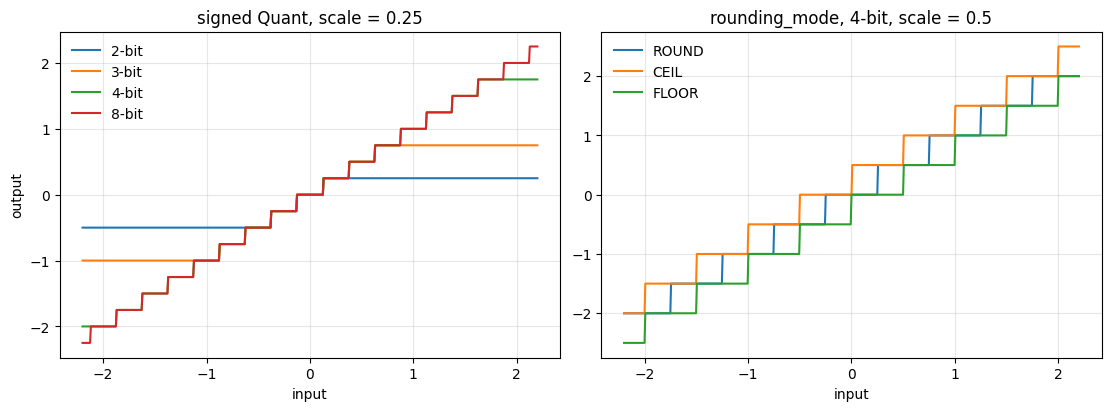

In [151]:
import matplotlib.pyplot as plt

ramp = np.linspace(-2.2, 2.2, 601).astype(np.float32)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)

for bw in [2, 3, 4, 8]:
    m = make_quant_model(scale=0.25, bitwidth=bw, n=ramp.size)
    axes[0].plot(ramp, oxe.execute_onnx(m, {"x": ramp})["y"], label=f"{bw}-bit")
axes[0].set(title="signed Quant, scale = 0.25", xlabel="input", ylabel="output")
axes[0].legend(frameon=False); axes[0].grid(alpha=.3)

for mode in ["ROUND", "CEIL", "FLOOR"]:
    m = make_quant_model(scale=0.5, bitwidth=4, rounding_mode=mode, n=ramp.size)
    axes[1].plot(ramp, oxe.execute_onnx(m, {"x": ramp})["y"], label=mode)
axes[1].set(title="rounding_mode, 4-bit, scale = 0.5", xlabel="input")
axes[1].legend(frameon=False); axes[1].grid(alpha=.3)
fig.savefig("fig_quant_staircase.png", dpi=150)
plt.show()

#### `narrow` and `signed`

`narrow=1` removes the most negative level so that the grid is symmetric about zero — this is
what you want when a hardware datapath cannot represent `-2^(b-1)`, and it is what Brevitas
emits for weights by default in several of its quantizers.

In [152]:
probe = np.linspace(-1.1, 1.1, 23).astype(np.float32)
for signed, narrow in [(1, 0), (1, 1), (0, 0)]:
    m = make_quant_model(scale=0.25, bitwidth=3, signed=signed, narrow=narrow, n=probe.size)
    levels = np.unique(oxe.execute_onnx(m, {"x": probe})["y"])
    print(f"signed={signed} narrow={narrow}: {len(levels)} levels -> {levels}")

signed=1 narrow=0: 8 levels -> [-1.   -0.75 -0.5  -0.25  0.    0.25  0.5   0.75]
signed=1 narrow=1: 7 levels -> [-0.75 -0.5  -0.25  0.    0.25  0.5   0.75]
signed=0 narrow=0: 5 levels -> [0.   0.25 0.5  0.75 1.  ]


### 2.3 `FloatQuant` — minifloat quantization

`FloatQuant` (added in QONNX 0.5 / carried into 1.0) describes **arbitrary minifloats**: you
give it an exponent width, a mantissa width, an exponent bias and a maximum value, and it
rounds to that floating-point grid. Setting `E4M3` reproduces the OCP FP8 format used by
current GPU and accelerator datapaths.

Inputs are `(x, scale, exponent_bitwidth, mantissa_bitwidth, exponent_bias, max_val)`.

In [153]:
def make_floatquant_model(ebits, mbits, bias, max_val, n):
    node = onnx.helper.make_node(
        "FloatQuant",
        inputs=["x", "scale", "ebw", "mbw", "ebias", "maxval"], outputs=["y"],
        domain=QONNX_DOMAIN, name="FloatQuant0",
        rounding_mode="ROUND", has_inf=0, has_nan=0, has_subnormal=1, saturation=1,
    )
    graph = onnx.helper.make_graph(
        [node], "floatquant_demo",
        [onnx.helper.make_tensor_value_info("x", onnx.TensorProto.FLOAT, [n])],
        [onnx.helper.make_tensor_value_info("y", onnx.TensorProto.FLOAT, [n])],
    )
    model = ModelWrapper(qonnx_make_model(graph, producer_name="floatquant-demo"))
    for name, val in [("scale", 1.0), ("ebw", ebits), ("mbw", mbits),
                      ("ebias", bias), ("maxval", max_val)]:
        model.set_initializer(name, np.float32(val))
    return model

xs = np.array([-3, -1.1, -0.6, -0.1, 0, 0.1, 0.6, 1.1, 3, 1000], dtype=np.float32)
e4m3 = make_floatquant_model(4, 3, 7, 480.0, xs.size)
print("E4M3 :", oxe.execute_onnx(e4m3, {"x": xs})["y"])

e5m2 = make_floatquant_model(5, 2, 15, 57344.0, xs.size)
print("E5M2 :", oxe.execute_onnx(e5m2, {"x": xs})["y"])
print("\nFLOAT<4,3> =", DataType["FLOAT<4,3>"].get_canonical_name(),
      "| max =", DataType["FLOAT<4,3>"].max())

E4M3 : [-3.000000e+00 -1.125000e+00 -6.250000e-01 -1.015625e-01  0.000000e+00
  1.015625e-01  6.250000e-01  1.125000e+00  3.000000e+00  4.800000e+02]
E5M2 : [-3.000e+00 -1.000e+00 -6.250e-01 -9.375e-02  0.000e+00  9.375e-02
  6.250e-01  1.000e+00  3.000e+00  1.024e+03]

FLOAT<4,3> = FLOAT<4,3,7> | max = 480.0


Unlike the integer grid, a minifloat grid is *non-uniform*: resolution is fine near zero and
coarse near the saturation point. That is exactly the property that makes it attractive for
weights and activations with heavy-tailed distributions.

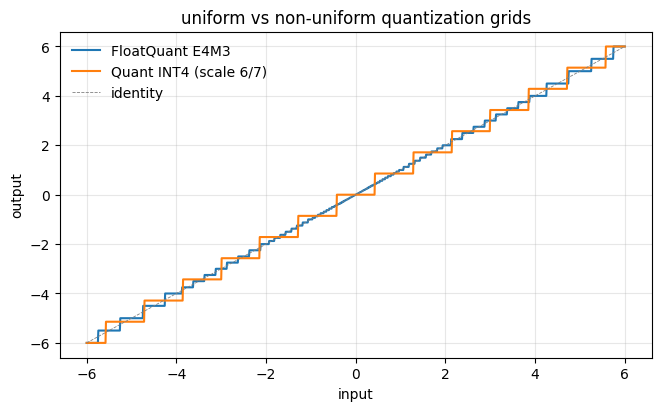

In [154]:
ramp2 = np.linspace(-6, 6, 1201).astype(np.float32)
fq = make_floatquant_model(4, 3, 7, 480.0, ramp2.size)
iq = make_quant_model(scale=6.0 / 7, bitwidth=4, n=ramp2.size)

fig, ax = plt.subplots(figsize=(6.5, 4), constrained_layout=True)
ax.plot(ramp2, oxe.execute_onnx(fq, {"x": ramp2})["y"], label="FloatQuant E4M3")
ax.plot(ramp2, oxe.execute_onnx(iq, {"x": ramp2})["y"], label="Quant INT4 (scale 6/7)")
ax.plot(ramp2, ramp2, lw=.6, ls="--", color="grey", label="identity")
ax.set(title="uniform vs non-uniform quantization grids", xlabel="input", ylabel="output")
ax.legend(frameon=False); ax.grid(alpha=.3)
fig.savefig("fig_float_vs_int.png", dpi=150)
plt.show()

### 2.4 The custom-op registry and operator versioning

QONNX 1.0 introduced **operator versioning** with "since-version" semantics, so a model that
imports `qonnx.custom_op.general` v1 keeps getting the v1 behaviour even after a new revision
of an op lands. `Trunc` is the first op with two revisions.

Note also that `Quant` is an alias that resolves to the `IntQuant` implementation class — the
op name in existing models is kept for compatibility.

In [155]:
from qonnx.custom_op.registry import getCustomOp, get_ops_in_domain, get_supported_versions

print("ops registered in qonnx.custom_op.general:")
for name, cls in sorted(get_ops_in_domain(QONNX_DOMAIN)):
    print(f"  {name:20s} -> {cls.__name__:18s} versions={get_supported_versions(QONNX_DOMAIN, name)}")

q_node = qmodel.get_nodes_by_op_type("Quant")[0]
inst = getCustomOp(q_node)
print("\nQuant node resolves to:", type(inst).__name__)
print("attributes:", inst.get_nodeattr_types())
print("rounding_mode =", inst.get_nodeattr("rounding_mode"))

ops registered in qonnx.custom_op.general:
  BipolarQuant         -> BipolarQuant       versions=[1]
  DebugMarker          -> DebugMarker        versions=[1]
  FloatQuant           -> FloatQuant         versions=[1]
  GenericPartition     -> GenericPartition   versions=[1]
  Im2Col               -> Im2Col             versions=[1]
  IntQuant             -> IntQuant           versions=[1]
  MaxPoolNHWC          -> MaxPoolNHWC        versions=[1]
  MultiThreshold       -> MultiThreshold     versions=[1]
  Quant                -> IntQuant           versions=[1]
  QuantAvgPool2d       -> QuantAvgPool2d     versions=[1]
  Trunc                -> Trunc_v2           versions=[1, 2]
  XnorPopcountMatMul   -> XnorPopcountMatMul versions=[1]

Quant node resolves to: IntQuant
attributes: {'signed': ('i', True, 1), 'narrow': ('i', True, 1), 'rounding_mode': ('s', False, 'ROUND')}
rounding_mode = ROUND


---
# 3. Working with real quantized models

### 3.1 Getting a model from the QONNX model zoo

The original tutorial fetched models with a hand-written `urllib` call. Two things went wrong
there and are worth pointing out, because they are easy mistakes to repeat:

* a GitHub **`/blob/`** URL serves an HTML page, not the file — you need **`/raw/`**;
* the repository name is case-sensitive (`QONNX_model_zoo`).

QONNX now ships `qonnx.util.test.download_model`, which knows the zoo layout, caches the file
and can hand you a `ModelWrapper` directly. Use it.

In [156]:
from qonnx.util.test import download_model, get_golden_in_and_output, get_random_input, test_model_details

for key, info in test_model_details.items():
    print(f"  {key:24s} {info['description']}")

  FINN-CNV_W2A2            2-bit VGG-10-like CNN on CIFAR-10
  FINN-CNV_W1A2            1/2-bit VGG-10-like CNN on CIFAR-10
  FINN-CNV_W1A1            1-bit VGG-10-like CNN on CIFAR-10
  FINN-TFC_W1A1            1-bit tiny MLP on MNIST
  FINN-TFC_W1A2            1/2-bit tiny MLP on MNIST
  FINN-TFC_W2A2            2-bit tiny MLP on MNIST
  RadioML_VGG10            8-bit VGG-10-like CNN on RadioML 2018
  Conv_bias_example        
  MobileNetv1-w4a4         4-bit MobileNet-v1 on ImageNet
  rn18_w4a4_a2q_16b        4-bit ResNet-18 on CIFAR-10, A2Q 16-bit accumulators
  rn18_w4a4_a2q_15b        4-bit ResNet-18 on CIFAR-10, A2Q 15-bit accumulators
  rn18_w4a4_a2q_14b        4-bit ResNet-18 on CIFAR-10, A2Q 14-bit accumulators
  rn18_w4a4_a2q_13b        4-bit ResNet-18 on CIFAR-10, A2Q 13-bit accumulators
  rn18_w4a4_a2q_12b        4-bit ResNet-18 on CIFAR-10, A2Q 12-bit accumulators
  rn18_w4a4_a2q_plus_16b   4-bit ResNet-18 on CIFAR-10, A2Q+ 16-bit accumulators
  rn18_w4a4_a2q_plus_15b   4

The zoo URLs point at `github.com`, which redirects to `raw.githubusercontent.com`. Some
networks block the first but not the second, so we add a one-line fallback that talks to
GitHub's raw-content host directly. On an unrestricted network the first attempt just works.

In [157]:
import urllib.error

def fetch_zoo_model(key, dl_dir="."):
    """download_model() with a fallback to GitHub's raw-content host."""
    try:
        return download_model(key, dl_dir=dl_dir)
    except (urllib.error.URLError, OSError) as e:
        print(f"[fetch_zoo_model] github.com unreachable ({type(e).__name__}); retrying via raw.githubusercontent.com")
        for info in test_model_details.values():
            info["url"] = (info["url"]
                           .replace("https://github.com/", "https://raw.githubusercontent.com/")
                           .replace("/raw/main/", "/main/"))
        return download_model(key, dl_dir=dl_dir)

tfc_path = fetch_zoo_model("FINN-TFC_W2A2")      # 2-bit MLP on MNIST, exported from Brevitas
print("downloaded:", tfc_path)

downloaded: ./FINN-TFC_W2A2.onnx


In [158]:
showInNetron(tfc_path)

[netron disabled] ./FINN-TFC_W2A2.onnx
graph 'torch-jit-export'   nodes: 31   initializers: 49
opset imports: [('<default>', 9)]   ir_version=6
  in  0                            [1, 1, 28, 28]  FLOAT32
  in  features.3.weight            [64]  FLOAT32
  in  features.3.bias              [64]  FLOAT32
  in  features.3.running_mean      [64]  FLOAT32
  in  features.3.running_var       [64]  FLOAT32
  in  features.7.weight            [64]  FLOAT32
  in  features.7.bias              [64]  FLOAT32
  in  features.7.running_mean      [64]  FLOAT32
  in  features.7.running_var       [64]  FLOAT32
  in  features.11.weight           [64]  FLOAT32
  in  features.11.bias             [64]  FLOAT32
  in  features.11.running_mean     [64]  FLOAT32
  in  features.11.running_var      [64]  FLOAT32
  in  features.15.weight           [1]  FLOAT32
  in  features.15.bias             [1]  FLOAT32
  in  features.15.running_mean     [1]  FLOAT32
  in  91                           [1]  FLOAT32
  in  92         

In [159]:
model = ModelWrapper(tfc_path)
summarize_model(model)

graph 'torch-jit-export'   nodes: 31   initializers: 49
opset imports: [('<default>', 9)]   ir_version=6
  in  0                            [1, 1, 28, 28]  FLOAT32
  in  features.3.weight            [64]  FLOAT32
  in  features.3.bias              [64]  FLOAT32
  in  features.3.running_mean      [64]  FLOAT32
  in  features.3.running_var       [64]  FLOAT32
  in  features.7.weight            [64]  FLOAT32
  in  features.7.bias              [64]  FLOAT32
  in  features.7.running_mean      [64]  FLOAT32
  in  features.7.running_var       [64]  FLOAT32
  in  features.11.weight           [64]  FLOAT32
  in  features.11.bias             [64]  FLOAT32
  in  features.11.running_mean     [64]  FLOAT32
  in  features.11.running_var      [64]  FLOAT32
  in  features.15.weight           [1]  FLOAT32
  in  features.15.bias             [1]  FLOAT32
  in  features.15.running_mean     [1]  FLOAT32
  in  91                           [1]  FLOAT32
  in  92                           [1]  FLOAT32
  in  25

### 3.2 Analysis passes

An *analysis pass* is any function `model -> dict`. You hand it to `model.analysis(fn)`, which
calls it with the model and returns its dictionary. Analysis passes never modify the graph.

In [160]:
showSrc(ModelWrapper.analysis)

    def analysis(
        self,
        analysis_fxn: Callable[["ModelWrapper", bool], T]
        | Callable[["ModelWrapper"], T],
        apply_to_subgraphs: bool = False,
    ) -> T:
        """Runs given anaylsis_fxn on this model and return resulting dict."""
        if apply_to_subgraphs:
            assert "apply_to_subgraphs" in inspect.signature(analysis_fxn).parameters, (
                "analysis_fxn must have 'apply_to_subgraphs' argument when apply_to_subgraphs == True"
            )
            return analysis_fxn(self, apply_to_subgraphs)  # type: ignore[call-arg]
        else:
            return analysis_fxn(self)  # type: ignore



#### Your own analysis pass

Counting node types is the canonical first example.

In [161]:
def count_unique_node_types(model):
    count_dict = {}
    for node in model.graph.node:
        count_dict[node.op_type] = count_dict.get(node.op_type, 0) + 1
    return count_dict

counts = model.analysis(count_unique_node_types)
for op, n in sorted(counts.items(), key=lambda kv: -kv[1]):
    print(f"  {op:22s} {n}")

  Quant                  8
  Transpose              4
  MatMul                 4
  BatchNormalization     3
  Mul                    2
  Sub                    2
  Shape                  1
  Gather                 1
  Unsqueeze              1
  Concat                 1
  Reshape                1
  Pow                    1
  Div                    1
  Add                    1


#### Built-in analysis passes

`qonnx.analysis.topology` ships sanity checks you should run before handing a model to any
compiler. A `False` here is a strong hint that a later transformation will misbehave.

* `nodes_topologically_sorted` — execution order is valid
* `all_tensors_f32` — every tensor is a `float32` container (the QONNX convention)
* `node_inputs_in_expected_order` — dynamic input first, parameters after, as QONNX passes assume
* `is_linear` — every tensor has fan-out <= 1, i.e. the graph has no branches

In [162]:
from qonnx.analysis.topology import (all_tensors_f32, node_inputs_in_expected_order,
                                     nodes_topologically_sorted, get_per_tensor_fanouts,
                                     is_linear)

for fn in (nodes_topologically_sorted, all_tensors_f32, node_inputs_in_expected_order, is_linear):
    print(f"  {fn.__name__:32s} {model.analysis(fn)}")

fanout = model.analysis(get_per_tensor_fanouts)
forks = {t: f for t, f in fanout.items() if f > 1}
print("\ntensors consumed more than once (fork points):", forks)

  nodes_topologically_sorted       {'nodes_topologically_sorted': True}
  all_tensors_f32                  {'all_tensors_f32': False}
  node_inputs_in_expected_order    {'node_inputs_in_expected_order': False}
  is_linear                        {'is_linear': False}

tensors consumed more than once (fork points): {'0': 2}


### 3.3 `cleanup` — the pass you should always run first

Models arriving from an exporter are rarely in canonical form: constant subgraphs that could
be folded, redundant `Identity`/`Squeeze` chains, missing shape annotations, legacy operator
domains. `qonnx.util.cleanup.cleanup_model` applies the standard tidy-up pipeline.

Watch what it does to this model: this file was exported by an **older Brevitas**, so its
`Quant` nodes still sit in the long-retired `onnx.brevitas` domain. Cleanup migrates them to
`qonnx.custom_op.general` — without that, `getCustomOp` would not find them.

In [163]:
from qonnx.util.cleanup import cleanup_model

print("BEFORE cleanup")
print("  nodes        :", len(model.graph.node))
print("  op types     :", sorted({n.op_type for n in model.graph.node}))
print("  Quant domain :", repr(model.get_nodes_by_op_type("Quant")[0].domain))

model_clean = cleanup_model(model)

print("\nAFTER cleanup")
print("  nodes        :", len(model_clean.graph.node))
print("  op types     :", sorted({n.op_type for n in model_clean.graph.node}))
print("  Quant domain :", repr(model_clean.get_nodes_by_op_type("Quant")[0].domain))
print("  removed      :", len(model.graph.node) - len(model_clean.graph.node), "nodes")
model_clean.save("TFC_W2A2_clean.onnx")

BEFORE cleanup
  nodes        : 31
  op types     : ['Add', 'BatchNormalization', 'Concat', 'Div', 'Gather', 'MatMul', 'Mul', 'Pow', 'Quant', 'Reshape', 'Shape', 'Sub', 'Transpose', 'Unsqueeze']
  Quant domain : 'onnx.brevitas'

AFTER cleanup
  nodes        : 22
  op types     : ['Add', 'BatchNormalization', 'Div', 'MatMul', 'Mul', 'Quant', 'Reshape', 'Sub']
  Quant domain : 'qonnx.custom_op.general'
  removed      : 9 nodes


`cleanup_model` is a composition of individual passes — you can read exactly which ones, and
call them selectively when you need finer control (`preserve_qnt_ops=False` lowers `Quant` nodes
away, `extract_conv_bias=True` splits `Conv` biases into separate `Add` nodes).

In [164]:
showSrc(cleanup_model)

def cleanup_model(model, preserve_qnt_ops=True, override_inpsize=None, extract_conv_bias=False):
    """Execute the transformations for the cleanup function on a model level.
    This allows the reuse of the cleanup transformations, without needing to read/write the model from/to disk.

    :param model: A raw QONNX model from as example Brevitas.
    :return model_clean: The cleaned model
    """

    # temporary fix for QONNX op domains
    qonnx_domain_ops = ["Quant", "Trunc", "BipolarQuant"]
    for q_op_type in qonnx_domain_ops:
        qnt_nodes = model.get_nodes_by_op_type(q_op_type)
        for qnt_node in qnt_nodes:
            qnt_node.domain = "qonnx.custom_op.general"
    if preserve_qnt_ops:
        preserve_qnt_optypes = ["Quant", "BipolarQuant", "QuantizeLinear", "DequantizeLinear"]
    else:
        preserve_qnt_optypes = []

    if override_inpsize is not None:
        if type(override_inpsize) is str:
            override_inpsize = eval(override_inpsize)
        if ty

### 3.4 Executing a quantized model and checking it against golden data

The zoo ships a reference input/output pair for each model. This is how you verify that *your*
QONNX installation reproduces the numbers the model author measured.

In [165]:
in_name  = model_clean.graph.input[0].name
out_name = model_clean.graph.output[0].name
print("input :", in_name, model_clean.get_tensor_shape(in_name))
print("output:", out_name, model_clean.get_tensor_shape(out_name))

golden_in, golden_out = get_golden_in_and_output("FINN-TFC_W2A2")
produced = oxe.execute_onnx(model_clean, {in_name: golden_in})[out_name]

print("\ngolden  :", np.round(golden_out.ravel(), 4))
print("produced:", np.round(produced.ravel(), 4))
print("max abs difference:", float(np.abs(produced - golden_out).max()))
assert np.isclose(produced, golden_out, atol=1e-4).all()
print("predicted class:", int(produced.argmax()))

input : global_in [1, 1, 28, 28]
output: global_out [1, 10]

golden  : [-1.1325 -1.9255 -0.8682 -0.4717 -1.485  -0.6479 -1.2206 -1.8815  0.057
 -1.6612]
produced: [-1.1325 -1.9255 -0.8682 -0.4717 -1.485  -0.6479 -1.2206 -1.8815  0.057
 -1.6612]
max abs difference: 0.0
predicted class: 8


`execute_onnx` can also return the **full execution context** — every intermediate tensor.
That is the fastest way to debug a quantization problem: look at where the dynamic range of an
activation collapses.

In [166]:
ctx = oxe.execute_onnx(model_clean, {in_name: golden_in}, return_full_exec_context=True)
print(f"{len(ctx)} tensors in the execution context\n")
for name, val in list(ctx.items())[:12]:
    v = np.asarray(val)
    print(f"  {name:26s} shape={str(v.shape):14s} unique={np.unique(v).size:>5d} "
          f"range=[{v.min():+.3f}, {v.max():+.3f}]")

71 tensors in the execution context

  global_in                  shape=(1, 1, 28, 28) unique=  784 range=[+0.005, +1.000]
  global_out                 shape=(1, 10)        unique=   10 range=[-1.926, +0.057]
  Reshape_0_out0             shape=(1, 784)       unique=  784 range=[+0.005, +1.000]
  Mul_0_out0                 shape=(1, 784)       unique=  784 range=[+0.010, +1.999]
  Sub_0_out0                 shape=(1, 784)       unique=  784 range=[-0.990, +0.999]
  Quant_4_out0               shape=(1, 784)       unique=    3 range=[-1.000, +1.000]
  Quant_0_out0               shape=(784, 64)      unique=    3 range=[-1.000, +1.000]
  MatMul_0_out0              shape=(1, 64)        unique=   36 range=[-22.000, +28.000]
  BatchNormalization_0_out0  shape=(1, 64)        unique=   64 range=[-7.433, +7.097]
  Quant_5_out0               shape=(1, 64)        unique=    3 range=[-1.000, +1.000]
  Quant_1_out0               shape=(64, 64)       unique=    3 range=[-1.000, +1.000]
  MatMul_1_out0

The `unique` column is informative: a tensor that is the output of a 2-bit `Quant` node can
take at most 4 distinct values, and you can see that directly.

### 3.5 Inference cost

`qonnx.util.inference_cost` estimates the arithmetic and memory footprint of a model,
*bit-width aware*. It is the standard way to compare quantization configurations before you
commit to a hardware build.

Its signature changed relative to older tutorials: it accepts a filename **or** a
`ModelWrapper`, and returns a dict keyed by `total_cost` (plus `optype_cost` and `node_cost`
when `cost_breakdown=True`).

Key quantities:

* `total_macs` — multiply-accumulate count, precision-independent
* `total_bops` — *bit* operations, $\sum \text{MACs} \times b_\text{weight} \times b_\text{act}$;
  the number that actually tracks FPGA/ASIC resource usage
* `total_mem_w_bits` — weight storage in bits
* `discount_sparsity` — when `True`, exact zeros in the weights are not counted

In [167]:
import json
from qonnx.util.inference_cost import inference_cost

cost = inference_cost(model_clean, discount_sparsity=False)["total_cost"]
print(json.dumps(cost, indent=2, default=str))

{
  "op_mac_INT2_INT2": 59008.0,
  "mem_w_INT2": 59008.0,
  "mem_o_INT32": 202.0,
  "unsupported": "set()",
  "discount_sparsity": false,
  "total_mem_w_bits": 118016.0,
  "total_mem_w_elems": 59008.0,
  "total_mem_o_bits": 6464.0,
  "total_mem_o_elems": 202.0,
  "total_bops": 236032.0,
  "total_macs": 59008.0
}


In [168]:
dense  = inference_cost(model_clean, discount_sparsity=False)["total_cost"]
sparse = inference_cost(model_clean, discount_sparsity=True)["total_cost"]
print(f"{'metric':22s} {'dense':>14s} {'sparsity-discounted':>22s}")
for k in ["total_macs", "total_bops", "total_mem_w_bits", "total_mem_o_bits"]:
    print(f"{k:22s} {dense[k]:14,.0f} {sparse[k]:22,.0f}")
print(f"\nzero-valued weights: {100*(1 - sparse['total_macs']/dense['total_macs']):.1f}%")

metric                          dense    sparsity-discounted
total_macs                     59,008                 22,355
total_bops                    236,032                 89,420
total_mem_w_bits              118,016                 44,710
total_mem_o_bits                6,464                  6,464

zero-valued weights: 62.1%


`cost_breakdown=True` adds a per-op-type and per-node view, which tells you *where* the cost
is — usually one or two layers dominate.

In [169]:
brk = inference_cost(model_clean, discount_sparsity=False, cost_breakdown=True)
print("per op type:")
for op, c in brk["optype_cost"].items():
    print(f"  {op:16s} bops={c.get('total_bops', 0):12,.0f}  macs={c.get('total_macs', 0):10,.0f}")

print("\ntop nodes by BOPs:")
nodes = sorted(brk["node_cost"].items(), key=lambda kv: -kv[1].get("total_bops", 0))
for name, c in nodes[:5]:
    print(f"  {name:24s} bops={c.get('total_bops', 0):12,.0f}")

per op type:
  MatMul           bops=     236,032  macs=    59,008

top nodes by BOPs:
  MatMul_0                 bops=     200,704
  MatMul_1                 bops=      16,384
  MatMul_2                 bops=      16,384
  MatMul_3                 bops=       2,560


Every one of these utilities also has a **command-line entry point**, which is what you
reach for in a CI pipeline:

```bash
qonnx-cleanup          model.onnx --out-file model_clean.onnx
qonnx-inference-cost   model.onnx --output-json cost.json --cost-breakdown
qonnx-exec             model.onnx input.npy
qonnx-convert          model.onnx          # Quant <-> QCDQ conversion
qonnx-to-channels-last model.onnx
qonnx-range-analysis   model.onnx
qonnx-download-model   FINN-TFC_W2A2
qonnx-prune-channels   model.onnx
```

---
# 4. Transformation passes

A *transformation pass* rewrites the graph. Where an analysis returns a dict, a transformation
returns `(model, model_was_changed)`.

### 4.1 `ModelWrapper.transform`

In [170]:
showSrc(ModelWrapper.transform)

    def transform(
        self,
        transformation: Transformation,
        make_deepcopy: bool = True,
        cleanup: bool = True,
        apply_to_subgraphs: bool = False,
        use_preorder_traversal: bool = True,
    ) -> ModelWrapper:
        """Applies given Transformation repeatedly until no more changes can be made
        and returns a transformed ModelWrapper instance.

        - make_deepcopy : operates on a new (deep)copy of model.
        - cleanup : execute cleanup transformations before returning
        - apply_to_subgraphs : if True, transformation is applied to all subgraphs of the model
        """
        transformed_model = self
        if make_deepcopy:
            transformed_model = copy.deepcopy(self)
        if self.fix_float64:
            (transformed_model, model_was_changed) = DoubleToSingleFloat().apply(
                transformed_model
            )

        if apply_to_subgraphs and (use_preorder_traversal is False):
            transformed_mo

Three things to take from that source:

1. **`make_deepcopy=True` by default** — `model.transform(T())` returns a *new* model and leaves
   the original alone. Pass `make_deepcopy=False` only when you are sure.
2. **The pass is applied repeatedly while it reports `model_was_changed=True`.** This lets a pass
   that rewrites one match at a time converge to a fixed point. It also means **a pass that
   always returns `True` loops forever** — the single most common bug when writing one.
3. **Subgraph traversal** (QONNX 1.0) — `transform_subgraphs` descends into `If`/`Loop` bodies,
   so control-flow subgraphs are no longer silently skipped.

In [171]:
from qonnx.transformation.base import Transformation
showSrc(Transformation)

class Transformation(ABC):
    """Transformation class all transformations are based on. Contains only
    abstract method apply() every transformation has to fill."""

    def __init__(self) -> None:
        super().__init__()

    @abstractmethod
    def apply(self, model: ModelWrapper) -> tuple[ModelWrapper, bool]:
        pass



### 4.2 Example — `ConvertSubToAdd`

A subtraction by a constant is an addition by its negation. This is the kind of canonicalisation
a hardware backend wants, because it has one adder, not two.

In [172]:
class ConvertSubToAdd(Transformation):
    """Replace Sub nodes that subtract a constant with Add nodes of the negated constant."""

    def apply(self, model):
        graph = model.graph
        converted = 0
        for n in graph.node:
            if n.op_type == "Sub":
                A = model.get_initializer(n.input[1])
                if A is not None:                 # only if the subtrahend is a constant
                    n.op_type = "Add"
                    model.set_initializer(n.input[1], -A)
                    converted += 1
        self.converted = converted
        return (model, False)                     # False: one pass over the graph is enough

sub_model = ModelWrapper("TFC_W2A2_clean.onnx")
print("Sub nodes before:", len(sub_model.get_nodes_by_op_type("Sub")))

t = ConvertSubToAdd()
sub_model_t = sub_model.transform(t)
print("converted       :", t.converted)
print("Sub nodes after :", len(sub_model_t.get_nodes_by_op_type("Sub")))
sub_model_t.save("TFC_W2A2_subtoadd.onnx")

Sub nodes before: 2
converted       : 2
Sub nodes after : 0


**A transformation you do not verify is a transformation you do not trust.** Run the golden
input through the rewritten graph and insist on the same answer.

> **This exact pass now ships with QONNX.** `qonnx.transformation.general.ConvertSubToAdd`
> (and its sibling `ConvertDivToMul`) do precisely this. We wrote it out by hand because it is
> the clearest possible example of the `Transformation` contract — in real code, import it.

In [173]:
after = oxe.execute_onnx(sub_model_t, {in_name: golden_in})[out_name]
print("max abs difference vs golden:", float(np.abs(after - golden_out).max()))
assert np.isclose(after, golden_out, atol=1e-4).all(), "ConvertSubToAdd changed the numerics!"
print("Numerics preserved.")

max abs difference vs golden: 0.0
Numerics preserved.


In [174]:
showInNetron("TFC_W2A2_subtoadd.onnx")

[netron disabled] TFC_W2A2_subtoadd.onnx
graph 'torch-jit-export'   nodes: 22   initializers: 47
opset imports: [('<default>', 9)]   ir_version=6
  in  global_in                    [1, 1, 28, 28]  FLOAT32
  out global_out                   [1, 10]  FLOAT32
  --------------------------------------------------------------------
    0 Quant [qonnx.custom_op.general]        ['Quant_0_param0', 'Quant_0_param1', 'Quant_0_param2', 'Quant_0_param3'] -> ['Quant_0_out0']
    1 Quant [qonnx.custom_op.general]        ['Quant_1_param0', 'Quant_1_param1', 'Quant_1_param2', 'Quant_1_param3'] -> ['Quant_1_out0']
    2 Quant [qonnx.custom_op.general]        ['Quant_2_param0', 'Quant_2_param1', 'Quant_2_param2', 'Quant_2_param3'] -> ['Quant_2_out0']
    3 Quant [qonnx.custom_op.general]        ['Quant_3_param0', 'Quant_3_param1', 'Quant_3_param2', 'Quant_3_param3'] -> ['Quant_3_out0']
    4 Reshape                                ['global_in', 'Reshape_0_param0'] -> ['Reshape_0_out0']
    5 Mul          

### 4.3 The built-in transformation library

You rarely need to write your own. QONNX ships a large catalogue; these are the ones you will
actually use.

In [175]:
import pkgutil
import qonnx.transformation as T

catalogue = {
    "infer_shapes":          "InferShapes — fill in missing tensor shapes",
    "infer_datatypes":       "InferDataTypes — propagate QONNX datatype annotations",
    "fold_constants":        "FoldConstants — evaluate constant subgraphs at compile time",
    "general":               "GiveUniqueNodeNames, GiveReadableTensorNames, RemoveIdentityOps, SortGraph, ...",
    "batchnorm_to_affine":   "BatchNormToAffine — BN -> Mul + Add (foldable into thresholds)",
    "gemm_to_matmul":        "GemmToMatMul — lower Gemm to MatMul (+Add); needs a bias input",
    "lower_convs_to_matmul": "LowerConvsToMatMul — Conv -> Im2Col + MatMul",
    "change_batchsize":      "ChangeBatchSize — re-batch a fixed-batch exported model",
    "change_datalayout":     "ChangeDataLayoutQuantAvgPool2d",
    "channels_last":         "ConvertToChannelsLastAndClean — NCHW -> NHWC for dataflow backends",
    "extract_conv_bias":     "ExtractBiasFromConv — split Conv bias into a separate Add",
    "extract_quant_scale_zeropt": "ExtractQuantScaleZeroPt — pull scale/zero-point out of Quant",
    "quant_constant_folding":"FoldTransposeIntoQuantInit and friends",
    "qonnx_to_qcdq":         "QuantToQCDQ — Quant -> QuantizeLinear/DequantizeLinear (standard ONNX)",
    "qcdq_to_qonnx":         "QCDQToQuant — the inverse direction",
    "quantize_graph":        "QuantizeGraph — insert Quant nodes into a float graph (PTQ-style)",
    "fixedpt_quantize":      "FixedPointQuantizeParamsFromDict — re-quantize initializers to fixed point",
    "pruning":               "PruneChannels — structured channel pruning",
    "rebalance_conv":        "RebalanceIm2Col",
    "resize_conv_to_deconv": "ResizeConvolutionToDeconvolution",
    "subpixel_to_deconv":    "SubPixelToDeconvolution",
    "expose_intermediate":   "ExposeIntermediateTensorsPatternFilter — add debug outputs",
    "insert":                "InsertIdentity / InsertIdentityOnAllTopLevelIO",
    "insert_topk":           "InsertTopK — append an argmax/top-k node",
    "merge_onnx_models":     "MergeONNXModels — concatenate two graphs",
    "remove":                "RemoveIdentityOps, RemoveUnusedTensors",
    "double_to_single_float":"DoubleToSingleFloat",
    "create_generic_partitions": "PartitionFromLambda — carve the graph into subgraphs",
}
available = sorted(m.name for m in pkgutil.iter_modules(T.__path__))
for mod in available:
    print(f"  qonnx.transformation.{mod:28s} {catalogue.get(mod, '')}")

  qonnx.transformation.base                         
  qonnx.transformation.batchnorm_to_affine          BatchNormToAffine — BN -> Mul + Add (foldable into thresholds)
  qonnx.transformation.bipolar_to_xnor              
  qonnx.transformation.change_3d_tensors_to_4d      
  qonnx.transformation.change_batchsize             ChangeBatchSize — re-batch a fixed-batch exported model
  qonnx.transformation.change_datalayout            ChangeDataLayoutQuantAvgPool2d
  qonnx.transformation.channels_last                ConvertToChannelsLastAndClean — NCHW -> NHWC for dataflow backends
  qonnx.transformation.composed                     
  qonnx.transformation.create_generic_partitions    PartitionFromLambda — carve the graph into subgraphs
  qonnx.transformation.double_to_single_float       DoubleToSingleFloat
  qonnx.transformation.expose_intermediate          ExposeIntermediateTensorsPatternFilter — add debug outputs
  qonnx.transformation.extend_partition             
  qonnx.transformation

#### Composing passes

Transformations chain. A realistic "prepare this model for a dataflow backend" pipeline looks
like the cell below. Note the ordering constraint: `ChangeBatchSize` deliberately **deletes all
intermediate shape annotations**, so it must be followed by `InferShapes`.

In [176]:
from qonnx.transformation.change_batchsize import ChangeBatchSize
from qonnx.transformation.infer_shapes import InferShapes
from qonnx.transformation.infer_datatypes import InferDataTypes
from qonnx.transformation.general import GiveUniqueNodeNames, GiveReadableTensorNames, RemoveStaticGraphInputs
from qonnx.transformation.batchnorm_to_affine import BatchNormToAffine

BATCH = 4
batched = (ModelWrapper("TFC_W2A2_clean.onnx")
           .transform(ChangeBatchSize(BATCH))
           .transform(InferShapes())              # <- mandatory after ChangeBatchSize
           .transform(InferDataTypes())
           .transform(GiveUniqueNodeNames())
           .transform(GiveReadableTensorNames())
           .transform(RemoveStaticGraphInputs()))

print("input shape:", batched.get_tensor_shape(batched.graph.input[0].name))
bi, bo = batched.graph.input[0].name, batched.graph.output[0].name
batch_in = np.repeat(golden_in, BATCH, axis=0)
batch_out = oxe.execute_onnx(batched, {bi: batch_in})[bo]
print("batched output shape:", batch_out.shape)
print("every row equals the golden output:",
      bool(np.isclose(batch_out, np.repeat(golden_out, BATCH, axis=0), atol=1e-4).all()))

input shape: [4, 1, 28, 28]
batched output shape: (4, 10)
every row equals the golden output: True


In [177]:
affine = cleanup_model(batched.transform(BatchNormToAffine()))
print("op types after BatchNormToAffine:", sorted({n.op_type for n in affine.graph.node}))
affine_out = oxe.execute_onnx(affine, {bi: batch_in})[bo]
print("max abs difference:", float(np.abs(affine_out - batch_out).max()))
assert np.isclose(affine_out, batch_out, atol=1e-4).all()
print("BatchNorm folded into Mul+Add with identical numerics.")

op types after BatchNormToAffine: ['Add', 'Div', 'MatMul', 'Mul', 'Quant', 'Reshape', 'Sub']
max abs difference: 0.0
BatchNorm folded into Mul+Add with identical numerics.


#### Channels-last conversion

Dataflow accelerators stream feature maps channel-last. `ConvertToChannelsLastAndClean` rewrites
an NCHW graph into NHWC, inserting the minimum number of transposes and folding the rest away.
This matters for convolutional models — let us use the 2-bit CNV from the zoo.

In [178]:
from qonnx.transformation.channels_last import ConvertToChannelsLastAndClean

cnv = cleanup_model(ModelWrapper(fetch_zoo_model("FINN-CNV_W2A2")))
cnv_in, cnv_out = cnv.graph.input[0].name, cnv.graph.output[0].name
x_cnv = get_random_input("FINN-CNV_W2A2")
ref_cnv = oxe.execute_onnx(cnv, {cnv_in: x_cnv})[cnv_out]

cnv_cl = cnv.transform(ConvertToChannelsLastAndClean())
print("NCHW op types:", sorted({n.op_type for n in cnv.graph.node}))
print("NHWC op types:", sorted({n.op_type for n in cnv_cl.graph.node}))
print("Transpose nodes NCHW->NHWC:",
      len(cnv.get_nodes_by_op_type("Transpose")), "->", len(cnv_cl.get_nodes_by_op_type("Transpose")))
got_cnv = oxe.execute_onnx(cnv_cl, {cnv_in: x_cnv})[cnv_out]
print("max abs difference:", float(np.abs(got_cnv - ref_cnv).max()))

NCHW op types: ['Add', 'BatchNormalization', 'Conv', 'Div', 'MatMul', 'MaxPool', 'Mul', 'Quant', 'Reshape', 'Sub']
NHWC op types: ['Add', 'BatchNormalization', 'Conv', 'Div', 'Flatten', 'MatMul', 'MaxPool', 'Mul', 'Quant', 'Sub', 'Transpose']
Transpose nodes NCHW->NHWC: 0 -> 1
max abs difference: 0.0


In [179]:
cnv_cost = inference_cost(cnv, discount_sparsity=False)["total_cost"]
tfc_cost = inference_cost(model_clean, discount_sparsity=False)["total_cost"]
print(f"{'model':16s} {'MACs':>12s} {'BOPs':>16s} {'weight bits':>14s}")
for name, c in [("TFC_W2A2 (MLP)", tfc_cost), ("CNV_W2A2 (CNN)", cnv_cost)]:
    print(f"{name:16s} {c['total_macs']:12,.0f} {c['total_bops']:16,.0f} {c['total_mem_w_bits']:14,.0f}")

model                    MACs             BOPs    weight bits
TFC_W2A2 (MLP)         59,008          236,032        118,016
CNV_W2A2 (CNN)     59,461,376      256,507,904      3,085,696


---
# 5. Brevitas — quantization-aware training

So far every quantized model came ready-made. Now we build one.

[Brevitas](https://github.com/Xilinx/brevitas) is a PyTorch library for **quantization-aware
training**. Instead of training in `float32` and rounding afterwards (post-training
quantization), it inserts the quantizers into the forward pass during training, so the network
*learns* weights that survive the rounding. Gradients flow through the quantizer with a
straight-through estimator.

Why this matters below ~8 bits: post-training quantization is usually fine at 8 bits and falls
apart at 4 bits and under, which is exactly the regime FPGA and ASIC inference lives in.

### 5.1 A dataset that works offline

A workshop should not depend on the conference wifi. We generate a deterministic synthetic
classification task: 10 class prototypes on a 16x16 binary grid, each sample a prototype with a
fraction of its pixels flipped plus additive Gaussian noise.

The difficulty is tuned so that the task is *learnable but not trivial* — a float network tops
out around 88%, which leaves visible headroom for quantization to eat into.

> Swap in MNIST by setting `USE_MNIST = True` if you have network access; everything downstream
> is shape-agnostic apart from `IMG`.

In [180]:
import torch
import torch.nn as nn

USE_MNIST = False          # set True for torchvision MNIST (needs network access)
IMG, NCLS, HIDDEN = 16, 10, 32
FLIP, NOISE = 0.35, 0.60

def make_synthetic(n_train=8000, n_test=2000, seed=0):
    g = np.random.default_rng(seed)
    protos = (g.random((NCLS, IMG * IMG)) < 0.35).astype(np.float32)
    def draw(n):
        y = g.integers(0, NCLS, n)
        X = protos[y].copy()
        flip = g.random(X.shape) < FLIP
        X[flip] = 1.0 - X[flip]
        X = np.clip(X + g.normal(0, NOISE, X.shape).astype(np.float32), 0, 1)
        return X.reshape(n, 1, IMG, IMG).astype(np.float32), y.astype(np.int64)
    return draw(n_train), draw(n_test), protos

if USE_MNIST:
    from torchvision import datasets, transforms
    tf = transforms.Compose([transforms.Resize(IMG), transforms.ToTensor()])
    tr_ds = datasets.MNIST("./data", train=True, download=True, transform=tf)
    te_ds = datasets.MNIST("./data", train=False, download=True, transform=tf)
    Xtr = torch.stack([tr_ds[i][0] for i in range(len(tr_ds))]).numpy()
    ytr = tr_ds.targets.numpy()
    Xte = torch.stack([te_ds[i][0] for i in range(len(te_ds))]).numpy()
    yte = te_ds.targets.numpy()
    protos = None
else:
    (Xtr, ytr), (Xte, yte), protos = make_synthetic()

print("train:", Xtr.shape, "test:", Xte.shape, "classes:", np.bincount(ytr))

train: (8000, 1, 16, 16) test: (2000, 1, 16, 16) classes: [821 817 766 796 758 852 819 777 828 766]


Plot the class prototypes next to the noisy samples the network actually sees. An individual
sample is close to unreadable by eye — the signal is there, but spread over 256 weakly
informative pixels, which is why a *linear* classifier does well and a human does not.

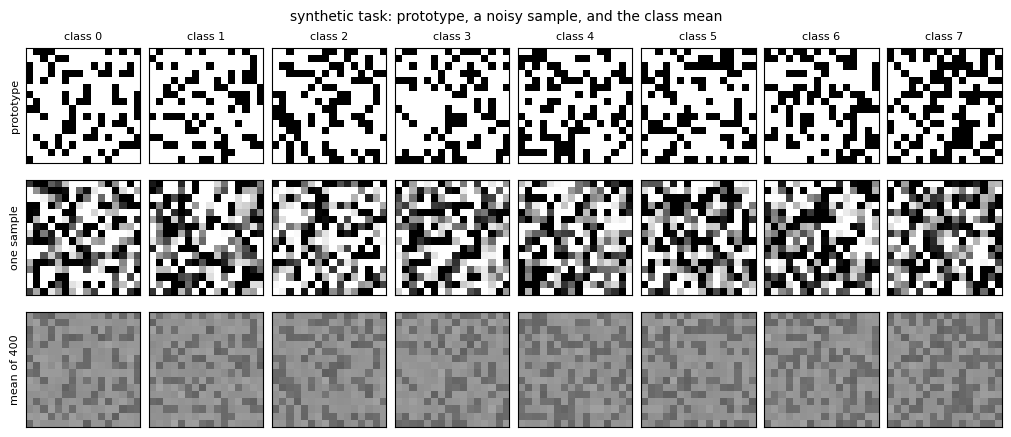

In [181]:
ncols = min(NCLS, 8)
fig, axes = plt.subplots(3, ncols, figsize=(1.25 * ncols, 4.3), constrained_layout=True)
for c in range(ncols):
    if protos is not None:
        axes[0, c].imshow(protos[c].reshape(IMG, IMG), cmap="gray_r", vmin=0, vmax=1)
    axes[0, c].set_title(f"class {c}", fontsize=8)
    idx = np.where(ytr == c)[0]
    axes[1, c].imshow(Xtr[idx[0], 0], cmap="gray_r", vmin=0, vmax=1)
    axes[2, c].imshow(Xtr[idx[:400], 0].mean(0), cmap="gray_r", vmin=0, vmax=1)
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
for row, label in enumerate(["prototype", "one sample", "mean of 400"]):
    axes[row, 0].set_ylabel(label, fontsize=8)
fig.suptitle("synthetic task: prototype, a noisy sample, and the class mean", fontsize=10)
fig.savefig("fig_dataset.png", dpi=150)
plt.show()

### 5.2 Building a quantized network with `brevitas.nn`

Brevitas mirrors `torch.nn`: `QuantLinear` for `Linear`, `QuantConv2d` for `Conv2d`,
`QuantReLU` for `ReLU`, plus `QuantIdentity` which quantizes a tensor without any other
operation — that is how you quantize the network *input*.

Two parameters do most of the work:

* **`weight_bit_width` / `bit_width`** — the precision of the weight or activation quantizer.
* **`return_quant_tensor`** — when `True` the layer emits a `QuantTensor`, which carries the
  value *together with* its scale, zero point, bit width and signedness. Downstream quantized
  layers use that metadata; it is also what makes the QONNX export able to annotate the graph.
  A layer feeding a plain `nn.Module` (or the loss) should return `False`.

The structure below — quantize input, quantized linear, batch norm, quantized ReLU, quantized
linear — is the canonical FINN-friendly MLP. Both linear layers carry a bias so that the
`GemmToMatMul` lowering in §6 has something to work with.

In [182]:
import brevitas.nn as qnn
from brevitas.quant import (Int8WeightPerTensorFloat, Int8ActPerTensorFloat,
                            SignedBinaryWeightPerTensorConst)

class QuantMLP(nn.Module):
    def __init__(self, weight_bits=4, act_bits=4, hidden=HIDDEN,
                 weight_quant=Int8WeightPerTensorFloat):
        super().__init__()
        self.inp = qnn.QuantIdentity(bit_width=8, return_quant_tensor=True)
        self.fc1 = qnn.QuantLinear(IMG * IMG, hidden, bias=True,
                                   weight_quant=weight_quant,
                                   weight_bit_width=weight_bits,
                                   return_quant_tensor=True)
        self.bn1 = nn.BatchNorm1d(hidden)
        self.act = qnn.QuantReLU(bit_width=act_bits, return_quant_tensor=True)
        self.fc2 = qnn.QuantLinear(hidden, NCLS, bias=True,
                                   weight_quant=weight_quant,
                                   weight_bit_width=weight_bits,
                                   return_quant_tensor=False)

    def forward(self, x):
        x = self.inp(x.reshape(x.shape[0], -1))
        x = self.act(self.bn1(self.fc1(x)))
        return self.fc2(x)

net = QuantMLP(weight_bits=4, act_bits=4)
print(net)

QuantMLP(
  (inp): QuantIdentity(
    (input_quant): ActQuantProxyFromInjector(
      (_zero_hw_sentinel): StatelessBuffer()
    )
    (act_quant): ActQuantProxyFromInjector(
      (_zero_hw_sentinel): StatelessBuffer()
      (fused_activation_quant_proxy): FusedActivationQuantProxy(
        (activation_impl): Identity()
        (tensor_quant): RescalingIntQuant(
          (int_quant): IntQuant(
            (float_to_int_impl): RoundSte()
            (tensor_clamp_impl): TensorClamp()
            (delay_wrapper): DelayWrapper(
              (delay_impl): _NoDelay()
            )
            (input_view_impl): Identity()
          )
          (scaling_impl): ParameterFromRuntimeStatsScaling(
            (stats_input_view_shape_impl): OverTensorView()
            (stats): _Stats(
              (stats_impl): AbsPercentile()
            )
            (restrict_scaling): _RestrictValue(
              (restrict_value_impl): FloatRestrictValue(
                (apply_abs): Abs()
             

#### Inspecting a `QuantTensor`

This is the object that distinguishes Brevitas from a plain PyTorch model: the tensor knows the
grid it lives on. `value` is the dequantized `float32` view; `int()` gives you the integer
representation that hardware would actually store.

In [183]:
net.eval()
with torch.no_grad():
    qt = net.inp(torch.from_numpy(Xte[:4]).reshape(4, -1))

print("type        :", type(qt).__name__)
print("value shape :", tuple(qt.value.shape))
print("scale       :", qt.scale.item())
print("zero_point  :", qt.zero_point.item())
print("bit_width   :", qt.bit_width.item())
print("signed      :", qt.signed)
print("int() dtype :", qt.int().dtype, " range:", int(qt.int().min()), "..", int(qt.int().max()))
print("distinct integer levels used:", int(torch.unique(qt.int()).numel()))

wq = net.fc1.quant_weight()
print("\nfc1 quantized weight: bit_width =", wq.bit_width.item(),
      "| scale =", float(wq.scale), "| distinct values =", int(torch.unique(wq.value).numel()))

type        : IntQuantTensor
value shape : (4, 256)
scale       : 0.0078125
zero_point  : 0.0
bit_width   : 8.0
signed      : True
int() dtype : torch.int8  range: 0 .. 127
distinct integer levels used: 121

fc1 quantized weight: bit_width = 4.0 | scale = 0.008927148766815662 | distinct values = 15


### 5.3 Training

A short QAT run. Nothing here is Brevitas-specific — the quantizers are just part of the
module, so the ordinary PyTorch training loop applies unchanged.

In [184]:
def train(model, epochs=6, lr=2e-3, batch_size=128, seed=0, verbose=True):
    torch.manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    lossf = nn.CrossEntropyLoss()
    dl = torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(torch.from_numpy(Xtr), torch.from_numpy(ytr)),
        batch_size=batch_size, shuffle=True)
    for ep in range(epochs):
        model.train()
        tot = 0.0
        for xb, yb in dl:
            opt.zero_grad()
            loss = lossf(model(xb), yb)
            loss.backward()
            opt.step()
            tot += loss.item() * xb.shape[0]
        if verbose:
            print(f"  epoch {ep+1}/{epochs}  train loss {tot/len(ytr):.4f}")
    return evaluate(model)

def evaluate(model):
    model.eval()
    with torch.no_grad():
        pred = model(torch.from_numpy(Xte)).argmax(1).numpy()
    return float((pred == yte).mean())

torch.manual_seed(0)
net = QuantMLP(weight_bits=4, act_bits=4)
acc_w4a4 = train(net)
print(f"\nW4A4 test accuracy: {acc_w4a4:.4f}")

  epoch 1/6  train loss 1.6467
  epoch 2/6  train loss 0.7120
  epoch 3/6  train loss 0.4258
  epoch 4/6  train loss 0.3270
  epoch 5/6  train loss 0.2786
  epoch 6/6  train loss 0.2432

W4A4 test accuracy: 0.8715


### 5.4 Pitfall: 1-bit weights need a *binary* quantizer

A natural guess is that `weight_bit_width=1` gives you a binary network. It does not work:
`Int8WeightPerTensorFloat` is an *integer* quantizer parameterised by bit width, and at one bit
its grid and its straight-through gradient degenerate — training collapses to chance level.

Binary weights need a dedicated quantizer such as `SignedBinaryWeightPerTensorConst`. This is
worth knowing before you spend an afternoon debugging a loss curve.

In [185]:
torch.manual_seed(0)
bad = QuantMLP(weight_bits=1, act_bits=2, weight_quant=Int8WeightPerTensorFloat)
acc_bad = train(bad, epochs=4, verbose=False)

torch.manual_seed(0)
good = QuantMLP(weight_bits=1, act_bits=2, weight_quant=SignedBinaryWeightPerTensorConst)
acc_good = train(good, epochs=6, verbose=False)

print(f"1-bit weights via Int8WeightPerTensorFloat      : {acc_bad:.4f}   <- chance is {1/NCLS:.2f}")
print(f"1-bit weights via SignedBinaryWeightPerTensorConst: {acc_good:.4f}")
print("\ndistinct weight values, fc1:",
      int(torch.unique(good.fc1.quant_weight().value).numel()), "(binary)")

1-bit weights via Int8WeightPerTensorFloat      : 0.0890   <- chance is 0.10
1-bit weights via SignedBinaryWeightPerTensorConst: 0.7445

distinct weight values, fc1: 2 (binary)


---
# 6. Brevitas → QONNX

### 6.1 Exporting

`brevitas.export.export_qonnx` traces the model and writes an ONNX file in which every Brevitas
quantizer has become a QONNX `Quant` node, with the learned scale and bit width baked in as
initializers.

The alternative, `export_onnx_qcdq`, writes *standard* ONNX using
`QuantizeLinear`/`DequantizeLinear`. We will produce both and compare in §6.6.

Note the opset line in the output: current Brevitas exports through the
`torch.export`/Dynamo path and imports **both** the default ONNX domain and
`qonnx.custom_op.general`.

In [186]:
from brevitas.export import export_qonnx, export_onnx_qcdq

dummy = torch.randn(1, 1, IMG, IMG)
export_qonnx(net, input_t=dummy, export_path="qmlp_w4a4.onnx")

exported = ModelWrapper("qmlp_w4a4.onnx")
summarize_model(exported)

[torch.onnx] Obtain model graph for `QuantMLP([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `QuantMLP([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
graph 'main_graph'   nodes: 9   initializers: 16
opset imports: [('<default>', 20), ('qonnx.custom_op.general', 2)]   ir_version=10
  in  x                            [1, 1, 16, 16]  FLOAT32
  in  fc1.bias                     [32]  FLOAT32
  in  bn1.weight                   [32]  FLOAT32
  in  bn1.bias                     [32]  FLOAT32
  in  fc2.bias                     [10]  FLOAT32
  in  bn1.running_mean             [32]  FLOAT32
  in  bn1.running_var              [32]  FLOAT32
  in  inp.act_quant.export_handler.lifted_tensor_0 []  FLOAT3

### 6.2 Cleanup and inspection

Run `cleanup_model` on anything that comes out of an exporter, then look at what the `Quant`
nodes actually say. Each one carries the bit width and scale the training run converged to.

In [187]:
exported_clean = cleanup_model(exported)
exported_clean.save("qmlp_w4a4_clean.onnx")
print("nodes:", len(exported.graph.node), "->", len(exported_clean.graph.node))
print("op types:", sorted({n.op_type for n in exported_clean.graph.node}))

print("\nQuant nodes:")
for n in exported_clean.get_nodes_by_op_type("Quant"):
    bw = exported_clean.get_initializer(n.input[3])
    sc = exported_clean.get_initializer(n.input[1])
    zp = exported_clean.get_initializer(n.input[2])
    signed = {a.name: a.i for a in n.attribute if a.name in ("signed", "narrow")}
    kind = "weight" if exported_clean.get_initializer(n.input[0]) is not None else "activation"
    print(f"  {n.name:12s} {kind:10s} bits={float(bw):.0f} "
          f"scale={np.asarray(sc).ravel()[0]:.6f} zeropt={np.asarray(zp).ravel()[0]:.0f} {signed}")

nodes: 9 -> 9
op types: ['BatchNormalization', 'Gemm', 'Quant', 'Relu', 'Reshape']

Quant nodes:
  Quant_0      weight     bits=4 scale=0.019564 zeropt=0 {'signed': 1, 'narrow': 1}
  Quant_1      weight     bits=4 scale=0.076070 zeropt=0 {'signed': 1, 'narrow': 1}
  Quant_2      activation bits=8 scale=0.008157 zeropt=0 {'signed': 1, 'narrow': 0}
  Quant_3      activation bits=4 scale=0.338986 zeropt=0 {'signed': 0, 'narrow': 0}


In [188]:
showInNetron("qmlp_w4a4_clean.onnx")

[netron disabled] qmlp_w4a4_clean.onnx
graph 'main_graph'   nodes: 9   initializers: 21
opset imports: [('<default>', 20), ('qonnx.custom_op.general', 2)]   ir_version=10
  in  global_in                    [1, 1, 16, 16]  FLOAT32
  out global_out                   [1, 10]  FLOAT32
  --------------------------------------------------------------------
    0 Reshape                                ['global_in', 'Reshape_0_param0'] -> ['Reshape_0_out0']
    1 Quant [qonnx.custom_op.general]        ['Quant_0_param0', 'Quant_0_param1', 'Quant_0_param2', 'Quant_0_param3'] -> ['Quant_0_out0']
    2 Quant [qonnx.custom_op.general]        ['Quant_1_param0', 'Quant_1_param1', 'Quant_1_param2', 'Quant_1_param3'] -> ['Quant_1_out0']
    3 Quant [qonnx.custom_op.general]        ['Reshape_0_out0', 'Quant_2_param0', 'Quant_2_param1', 'Quant_2_param2'] -> ['Quant_2_out0']
    4 Gemm                                   ['Quant_2_out0', 'Quant_0_out0', 'Gemm_0_param0'] -> ['Gemm_0_out0']
    5 BatchNormali

### 6.3 Does the exported graph compute the same thing?

This is the single most important check in the whole notebook. Export is a translation between
two different implementations of the same arithmetic, and translations have bugs. Run the same
inputs through PyTorch and through `execute_onnx` and look at the difference.

The exported graph has a **fixed batch size of 1** (the exporter bakes in `dummy`'s shape), so
feed it one sample at a time for now — §6.4 fixes that.

In [189]:
probe = Xte[:16]
net.eval()
with torch.no_grad():
    ref_torch = net(torch.from_numpy(probe)).numpy()

ei, eo = exported_clean.graph.input[0].name, exported_clean.graph.output[0].name
got_qonnx = np.concatenate([oxe.execute_onnx(exported_clean, {ei: probe[i:i+1]})[eo]
                            for i in range(len(probe))])

print("max abs difference (Brevitas vs QONNX):", float(np.abs(ref_torch - got_qonnx).max()))
print("predictions agree on all samples      :",
      bool((ref_torch.argmax(1) == got_qonnx.argmax(1)).all()))
assert np.allclose(ref_torch, got_qonnx, atol=1e-4)

max abs difference (Brevitas vs QONNX): 9.5367431640625e-07
predictions agree on all samples      : True


### 6.4 Re-batching the exported model

`ChangeBatchSize` + `InferShapes` turns the batch-1 export into a batch-N graph.

In [190]:
exported_batched = (exported_clean
                    .transform(ChangeBatchSize(len(probe)))
                    .transform(InferShapes()))
print("input shape:", exported_batched.get_tensor_shape(ei))

got_batched = oxe.execute_onnx(exported_batched, {ei: probe})[eo]
print("max abs difference:", float(np.abs(ref_torch - got_batched).max()))

input shape: [16, 1, 16, 16]
max abs difference: 0.0


We can now also lower `Gemm` to `MatMul` + `Add`, which is the form dataflow backends expect.

> **Known limitation.** `GemmToMatMul` reads `node.input[2]`, so it requires a `Gemm` that
> *has* a bias input. A `QuantLinear(..., bias=False)` exports to a two-input `Gemm` and the
> pass raises `IndexError`. That is why both layers above were given a bias.

In [191]:
from qonnx.transformation.gemm_to_matmul import GemmToMatMul

lowered = cleanup_model(exported_batched.transform(GemmToMatMul()))
print("op types:", sorted({n.op_type for n in lowered.graph.node}))
got_lowered = oxe.execute_onnx(lowered, {ei: probe})[eo]
print("max abs difference:", float(np.abs(ref_torch - got_lowered).max()))
assert np.allclose(ref_torch, got_lowered, atol=1e-4)

op types: ['Add', 'BatchNormalization', 'MatMul', 'Quant', 'Relu', 'Reshape']
max abs difference: 0.0


/usr/local/lib/python3.13/dist-packages/qonnx/transformation/gemm_to_matmul.py:57: UserWarning: The GemmToMatMul transformation only offers explicit support for version 9 of the Gemm node, but the ONNX version of the supplied model is 20. Thus the transformation may fail or return incomplete results.
  warnings.warn(


### 6.5 Bit width versus cost

Now the question the whole toolchain exists to answer: **what does precision buy, and what does
it cost?**

We train the same architecture at several weight/activation precisions, export each one, and
read the cost off the exported graph with `inference_cost`. BOPs — MACs weighted by the product
of operand bit widths — is the figure of merit that tracks FPGA LUT/DSP usage.

Each configuration trains in a few seconds. Results are from a single seed; treat small
accuracy differences as noise.

In [192]:
import time

configs = [
    ("W8A8", 8, 8, Int8WeightPerTensorFloat,          6),
    ("W4A4", 4, 4, Int8WeightPerTensorFloat,          6),
    ("W3A3", 3, 3, Int8WeightPerTensorFloat,          6),
    ("W2A2", 2, 2, Int8WeightPerTensorFloat,          6),
    ("W1A2", 1, 2, SignedBinaryWeightPerTensorConst,  6),
]

results = []
t0 = time.time()
for tag, wb, ab, wq, epochs in configs:
    torch.manual_seed(0)
    m = QuantMLP(weight_bits=wb, act_bits=ab, weight_quant=wq)
    acc = train(m, epochs=epochs, verbose=False)
    path = f"qmlp_{tag}.onnx"
    export_qonnx(m, input_t=dummy, export_path=path)
    mc = cleanup_model(ModelWrapper(path))
    cost = inference_cost(mc, discount_sparsity=False)["total_cost"]
    wdtype = ", ".join(sorted(k[len("mem_w_"):] for k in cost if k.startswith("mem_w_")))
    results.append(dict(tag=tag, w=wb, a=ab, acc=acc, wdtype=wdtype,
                        macs=cost["total_macs"], bops=cost["total_bops"],
                        wbits=cost["total_mem_w_bits"]))
    print(f"  {tag}: acc={acc:.4f}  BOPs={cost['total_bops']:>12,.0f}  "
          f"weights={cost['total_mem_w_bits']:>8,.0f} bits   [{time.time()-t0:.0f}s]")

[torch.onnx] Obtain model graph for `QuantMLP([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `QuantMLP([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
  W8A8: acc=0.8700  BOPs=     544,768  weights=  68,096 bits   [7s]
[torch.onnx] Obtain model graph for `QuantMLP([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `QuantMLP([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
  W4A4: acc=0.8715  BOPs

In [193]:
print(f"{'config':8s} {'acc':>7s} {'MACs':>10s} {'BOPs':>14s} {'weight bits':>13s} "
      f"{'BOPs vs W8A8':>13s}  weight datatype")
base = results[0]["bops"]
for r in results:
    print(f"{r['tag']:8s} {r['acc']:7.4f} {r['macs']:10,.0f} {r['bops']:14,.0f} "
          f"{r['wbits']:13,.0f} {base/r['bops']:12.1f}x  {r['wdtype']}")

config       acc       MACs           BOPs   weight bits  BOPs vs W8A8  weight datatype
W8A8      0.8700      8,512        544,768        68,096          1.0x  SCALEDINT<8>
W4A4      0.8715      8,512        267,264        34,048          2.0x  SCALEDINT<4>
W3A3      0.8615      8,512        199,488        25,536          2.7x  SCALEDINT<3>
W2A2      0.8185      8,512        132,352        17,024          4.1x  SCALEDINT<2>
W1A2      0.7445      8,512      2,117,632       272,384          0.3x  FLOAT32


### A caveat you must read before trusting the W1A2 row

Look at the weight-datatype column: the binary configuration reports **`FLOAT32` weights**, and
consequently a *higher* BOPs count than the 8-bit model. That is not what the hardware would do —
it is a gap in the cost model.

`SignedBinaryWeightPerTensorConst` exports to a **`BipolarQuant`** node rather than a `Quant`
node, and `InferDataTypes` in QONNX 1.0.0 does not derive a `BIPOLAR` annotation from it. Since
`inference_cost` reads the *annotation*, not the node, it falls back to `FLOAT32` and
over-reports binary weights by a factor of 32. Annotating the tensor by hand does not help
either — the next `InferDataTypes` pass overwrites it.

The honest thing to do is exclude the binary point from the cost curve and say why. Its
*accuracy* is still a valid measurement; only its cost is not comparable. The expected value, if
the annotation were right, is `8512 bits` of weight memory and `~2x` fewer BOPs than W2A2.

This is the kind of thing you find only by checking cost numbers against a sanity expectation —
worth doing every time, and worth reporting upstream when it does not hold.

In [194]:
comparable = [r for r in results if "FLOAT32" not in r["wdtype"]]
flagged    = [r for r in results if "FLOAT32" in r["wdtype"]]
print("cost-comparable configs:", [r["tag"] for r in comparable])
print("excluded from cost plots:", [r["tag"] for r in flagged],
      "(weights not recognised as quantized)")

cost-comparable configs: ['W8A8', 'W4A4', 'W3A3', 'W2A2']
excluded from cost plots: ['W1A2'] (weights not recognised as quantized)


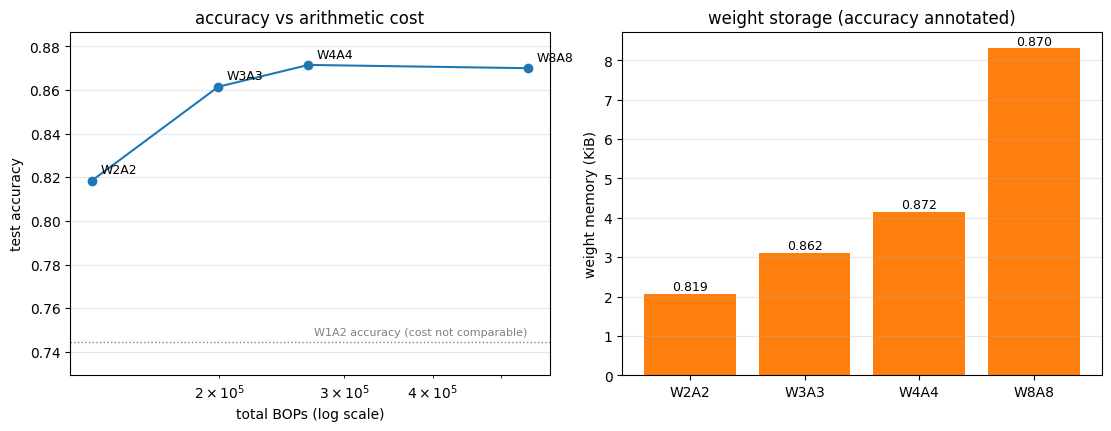

In [195]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)

curve = sorted(comparable, key=lambda r: r["bops"])
axes[0].plot([r["bops"] for r in curve], [r["acc"] for r in curve], "o-", color="#1f77b4")
for r in curve:
    axes[0].annotate(r["tag"], (r["bops"], r["acc"]),
                     textcoords="offset points", xytext=(6, 5), fontsize=9)
for r in flagged:                       # accuracy only: cost not comparable (see note above)
    axes[0].axhline(r["acc"], ls=":", lw=1, color="grey")
    axes[0].annotate(f"{r['tag']} accuracy (cost not comparable)",
                     (max(r_["bops"] for r_ in curve), r["acc"]),
                     ha="right", textcoords="offset points", xytext=(0, 5),
                     fontsize=8, color="grey")
axes[0].margins(y=0.12)
axes[0].set(xscale="log", xlabel="total BOPs (log scale)", ylabel="test accuracy",
            title="accuracy vs arithmetic cost")
axes[0].grid(alpha=.3)

axes[1].bar([r["tag"] for r in curve], [r["wbits"] / 8 / 1024 for r in curve], color="#ff7f0e")
axes[1].set(ylabel="weight memory (KiB)", title="weight storage (accuracy annotated)")
axes[1].grid(alpha=.3, axis="y")
for i, r in enumerate(curve):
    axes[1].text(i, r["wbits"] / 8 / 1024, f"{r['acc']:.3f}", ha="center", va="bottom", fontsize=9)

fig.savefig("fig_bitwidth_sweep.png", dpi=150)
plt.show()

Read the left panel right to left: dropping from 8-bit to 2-bit weights and activations cuts
BOPs by roughly a factor of four for about five points of accuracy, and the knee of that curve
sits around 3 bits. That curve — not a single accuracy number — is what you present when you
argue for a precision choice.

The right panel shows the other half of the story: weight memory falls linearly in weight bit
width, which on an FPGA decides whether the parameters fit in on-chip BRAM at all.

### 6.6 QONNX → QCDQ: running a quantized model in standard ONNX Runtime

QONNX's `Quant` node is not standard ONNX, so `onnxruntime` cannot execute it (§2.2). The
`QuantToQCDQ` transformation rewrites each `Quant` into the standard
`QuantizeLinear` → (`Clip`) → `DequantizeLinear` pattern, giving you a file that any ONNX
consumer can load.

The `Clip` is what encodes sub-8-bit precision: `QuantizeLinear` stores into an `int8`
container, and the clip restricts it to the `[-2^(b-1), 2^(b-1)-1]` sub-range. The arithmetic
is identical; only the *expression* changes.

In [196]:
from qonnx.transformation.qonnx_to_qcdq import QuantToQCDQ

qcdq = exported_batched.transform(QuantToQCDQ())
qcdq.save("qmlp_w4a4_qcdq.onnx")
print("QONNX op types:", sorted({n.op_type for n in exported_batched.graph.node}))
print("QCDQ  op types:", sorted({n.op_type for n in qcdq.graph.node}))
print("Quant nodes:", len(exported_batched.get_nodes_by_op_type("Quant")),
      "-> QuantizeLinear/DequantizeLinear:",
      len(qcdq.get_nodes_by_op_type("QuantizeLinear")),
      "/", len(qcdq.get_nodes_by_op_type("DequantizeLinear")))

QONNX op types: ['BatchNormalization', 'Gemm', 'Quant', 'Relu', 'Reshape']
QCDQ  op types: ['BatchNormalization', 'Clip', 'Constant', 'DequantizeLinear', 'Gemm', 'QuantizeLinear', 'Relu', 'Reshape']
Quant nodes: 4 -> QuantizeLinear/DequantizeLinear: 4 / 4


In [197]:
sess = ort_session(qcdq)
got_ort = sess.run(None, {sess.get_inputs()[0].name: probe})[0]
print("max abs difference (Brevitas vs QCDQ in onnxruntime):",
      float(np.abs(ref_torch - got_ort).max()))
print("predictions agree:", bool((ref_torch.argmax(1) == got_ort.argmax(1)).all()))

max abs difference (Brevitas vs QCDQ in onnxruntime): 0.0
predictions agree: True


Brevitas can also emit QCDQ directly, without going through QONNX at all.

In [198]:
export_onnx_qcdq(net, input_t=dummy, export_path="qmlp_w4a4_qcdq_brevitas.onnx",
                 opset_version=17)
direct = ModelWrapper("qmlp_w4a4_qcdq_brevitas.onnx")
print("op types:", sorted({n.op_type for n in direct.graph.node}))
print("opset   :", [(o.domain or "<default>", o.version) for o in direct.model.opset_import])

sess_d = ort_session(direct)
got_direct = np.concatenate([sess_d.run(None, {sess_d.get_inputs()[0].name: probe[i:i+1]})[0]
                             for i in range(len(probe))])
print("max abs difference vs Brevitas:", float(np.abs(ref_torch - got_direct).max()))

W1019 09:57:10.986000 1545 torch/onnx/_internal/exporter/_compat.py:133] Setting ONNX exporter to use operator set version 18 because the requested opset_version 17 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features


[torch.onnx] Obtain model graph for `QuantMLP([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `QuantMLP([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
op types: ['BatchNormalization', 'Clip', 'DequantizeLinear', 'Gemm', 'QuantizeLinear', 'Relu', 'Reshape']
opset   : [('<default>', 17)]
max abs difference vs Brevitas: 9.5367431640625e-07


#### Which export should you use?

| | `export_qonnx` (QONNX) | `export_onnx_qcdq` / `QuantToQCDQ` |
|---|---|---|
| bit widths | arbitrary (1–32) | integer containers only (8-bit, 4-bit in new opsets) |
| consumers | FINN, hls4ml, QONNX tooling | onnxruntime, TensorRT, any standard ONNX runtime |
| graph | compact, one `Quant` per quantizer | `QuantizeLinear`/`Clip`/`DequantizeLinear` triplets |
| use it for | FPGA/ASIC toolchains, cost analysis, sub-8-bit research | CPU/GPU deployment, interoperability, sanity checks |

In practice: **export QONNX** as your source of truth, and convert to QCDQ when you need to run
the model somewhere that only speaks standard ONNX. Converting is one transformation, and as the
cell above shows the numerics come out bit-identical.

---
# 7. Where to go next

**Toolchains that consume QONNX**

* [FINN](https://github.com/Xilinx/finn) — dataflow FPGA accelerators from QONNX graphs. The
  `ConvertQONNXtoFINN` entry point takes exactly the kind of file §6 produced.
* [hls4ml](https://github.com/fastmachinelearning/hls4ml) — HLS inference for FPGAs and ASICs,
  with a QONNX frontend.

**More QONNX to explore**

* `qonnx.util.range_analysis` — propagate input ranges through the graph to find dead or
  "stuck" channels, and to pick activation scales without a calibration run.
* `qonnx.transformation.pruning.PruneChannels` — structured channel pruning.
* `qonnx.transformation.quantize_graph.QuantizeGraph` — insert `Quant` nodes into a *float*
  graph, i.e. post-training quantization inside QONNX.
* `qonnx.transformation.expose_intermediate` — add graph outputs for intermediate tensors to
  compare layer-by-layer against PyTorch.
* `qonnx.core.onnx_exec.compare_execution` — diff two models tensor by tensor.

**More Brevitas to explore**

* `brevitas.quant` — the quantizer zoo: per-channel scales, learned scales (`ParameterFromRuntime`),
  power-of-two scales (`PoTScaling`, cheap in hardware), ternary and bipolar.
* `brevitas.graph.quantize.preprocess_for_quantize` + `quantize_model` — automatically convert an
  existing `torch.nn` model to its quantized equivalent.
* Accumulator-aware quantization (A2Q) — constrain the *accumulator* width, not just weights and
  activations. The `rn18_w4a4_a2q_*` entries in the model zoo are trained this way.

**Model zoo** — <https://github.com/fastmachinelearning/QONNX_model_zoo>, reachable from Python
with `qonnx.util.test.download_model`.